**Background and Problem Statement**

TagPro (https://tagpro.koalabeast.com/) is a free-to-play online 2-D capture the flag game in which players roll around a tiled map as paint-filled balls. Typically, the matches are played 4v4 with two players on each team on defense and the other two players on offense. While it can be a fun casual game, there is a staunch competitive community centered the game as well, not unlike the competitive scene around SSB Melee. Several regions (NA, EU, OCE) have professional leagues (MLTP, ELTP, OLTP respectively) where the best of the best battle it out to see who reigns supreme. There is a lot of raw data collected and recorded from each of these competitive matches, which are then reported either as is or used to construct more complex statistics. Going another step further, those statistics are then used to judge player performance, both directly by examining the leaders in each category and also by using comparison metrics that lump together several other statistics and weighting them appropriately.

This begs the question: "How do we choose the subcomponents of the player comparison metric in a reasonable manner, and subsequently weight them appropriately?" One reasonable approach to gathering information to this end is to use deep learning neural networks to try to predict whether a player had a winning season based on their stats. We could define a winning season as having a positive cap differential; that is, the player's team scored more caps than they allowed their opponents to score against them. Figuring out which statistics are the most important for winning is crucial for players looking to improve their game, for general managers to decide which players they want to draft to their team, and for award voters to decide which players helped their teams the most. We would like to employ binary classification techniques to build models using deep learning to try to separate players into two classes, winners and losers.

We will look at data from the games of North American pro league, MLTP, spanning over two dozen seasons of matches. The data for each individual season is stored separately on a site called TagPro League, or TPL for short. We will need to scrape the raw data for each season and amalgamate everything, along with doing some non-trivial cleaning and preprocessing work.

[1] TagPro League. Available at: https://www.tagproleague.com/MLTP/stats (Accessed: April 22, 2023). 

In [2]:
#!pip install tensorflow
#!pip install keras

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import os
import warnings
import itertools
import plotly.express as px


# warnings.filterwarnings('ignore', category=DeprecationWarning)
df = pd.read_csv('C:\\Users\\jshap\\OneDrive\\Desktop\\Stats\\MLTP_S10_majors_cumulative.tsv', delimiter = '\t', engine = 'python')
print(df)

           player team  score  minutes  pm  tags  pops  grabs  drops  hold  \
0         Altiger  NaN   1462      360   9   357   551    507    459  4078   
1      Blue Dream  NaN    143       40  -5    34    76     67     60   469   
2    Death Pickle  NaN   1579      400 -16   604   310    182    174  1461   
3         BigBird  NaN   1680      400  -4   550   284    170    158  1156   
4           Vials  NaN   1295      400 -16   286   645    594    542  4400   
..            ...  ...    ...      ...  ..   ...   ...    ...    ...   ...   
130       #Frozen  NaN     77       30 -19    31    66     57     54   227   
131       DUBSTEP  NaN     91       40 -28    28   102     83     77   353   
132     alchemist  NaN    105       40 -28    46    45     23     22   116   
133        Shabba  NaN     82       40 -28    29    74     60     57   276   
134  fenix funk 5  NaN    121       40 -28    59    53     26     26    82   

     ...  goodhandoff  goregrab  coregrab  gohandoff  cohandoff

We can see that there is no column to denote which season the data is from, so we will need to add that information into the master dataset as we weld the individual datasets together. By consulting with our Subject Matter Expert, we are also aware that there is an important shift that occurs starting in Season 20. Prior to that, most of the matches were played on teams' home servers, while in S20 and onwards all teams played on the Dallas-based server, resulting in much higher average ping for most players. To capture this critical rule change, we will also append a binary variable that tracks whether the season was played on Dallas or not.  

**Building the Master Dataset**

In [4]:
# Define the directory containing the TSV files
directory = 'C:\\Users\\jshap\\OneDrive\\Desktop\\Stats\\'

# Get a list of all TSV files in the directory
tsv_files = [os.path.join(directory, file) for file in os.listdir(directory) if file.endswith('.tsv')]

# Initialize an empty DataFrame to hold the data
MLTP_master_stats = pd.DataFrame()

# Loop over each TSV file and load it into a DataFrame
for i, location in enumerate(tsv_files):
    temp = pd.read_csv(location, sep = '\t', header = 0, na_values = [''], low_memory = False)
    season = i + 10
    Dallas = 0
    
    if season >= 20:
        Dallas = 1
    
    temp['Dallas'] = Dallas        
    temp['season'] = season
    MLTP_master_stats = MLTP_master_stats.append(temp, ignore_index=True)

# Convert necessary columns to factors
MLTP_master_stats['season'] = pd.Categorical(MLTP_master_stats['season'])
MLTP_master_stats['Dallas'] = pd.Categorical(MLTP_master_stats['Dallas'])

#Add ratio metrics (should NOT be per minute) 
MLTP_master_stats['kdr'] = MLTP_master_stats['tags'] / MLTP_master_stats['pops']
MLTP_master_stats['score_%'] = 100 * MLTP_master_stats['captures'] / MLTP_master_stats['grabs']

# Print the resulting DataFrame
print(MLTP_master_stats)
size = MLTP_master_stats.shape

            player team  score  minutes  pm  tags  pops  grabs  drops  hold  \
0          Altiger  NaN   1462      360   9   357   551    507    459  4078   
1       Blue Dream  NaN    143       40  -5    34    76     67     60   469   
2     Death Pickle  NaN   1579      400 -16   604   310    182    174  1461   
3          BigBird  NaN   1680      400  -4   550   284    170    158  1156   
4            Vials  NaN   1295      400 -16   286   645    594    542  4400   
...            ...  ...    ...      ...  ..   ...   ...    ...    ...   ...   
1307          Nati  TRT    159       50  10    65    50     40     39   186   
1308           bbb  ROJ    217       50   6    72    50     35     32   331   
1309          EIsa  NaN    165       50   3    34    86     83     74   472   
1310   TheEpicBlob  TGB    201       70   4    70    62     30     29   114   
1311       Pie Cat  NaN    196       50   8    54    69     63     54   426   

      ...  cohandoff  retinbase  quickret  saves  h

C:\Users\jshap\AppData\Local\Temp\ipykernel_32264\1497623423.py:21: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  MLTP_master_stats = MLTP_master_stats.append(temp, ignore_index=True)
C:\Users\jshap\AppData\Local\Temp\ipykernel_32264\1497623423.py:21: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  MLTP_master_stats = MLTP_master_stats.append(temp, ignore_index=True)
C:\Users\jshap\AppData\Local\Temp\ipykernel_32264\1497623423.py:21: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pandas.concat instead.
  MLTP_master_stats = MLTP_master_stats.append(temp, ignore_index=True)
C:\Users\jshap\AppData\Local\Temp\ipykernel_32264\1497623423.py:21: FutureWarning: The frame.append method is deprecated and will be removed from pandas in a future version. Use pan

Now we have our full master dataset in all its glory! Let's investigate its properties a bit before getting ahead of ourselves with the data cleaning steps. We can see that we have 1312 observations, each containing 28 innate features and the four extra that we tacked on while creating the master dataset for a total of 32 features. The features 'Player' and 'team' are strings, 'Dallas' and 'season' are categorical features, 'Unnamed: 27' is a column full of all NaN values, and the other 27 features are various numeric integer statistical measures directly captured from the gameplay or calculated from directly captured data (such as Kill/Death Ratio and Scoring Percentage).

**Data Cleaning**

Let's programmatically check for missing values in each column for starters, in case the summary earlier didn't get the full picture:

In [5]:
for col in MLTP_master_stats.columns:
    temp = MLTP_master_stats[col].isna().sum()
    print(f"Missing values in feature '{col}': {temp} out of {size[0]}, or {round(100 * temp / size[0], 1)}% missing")

Missing values in feature 'player': 0 out of 1312, or 0.0% missing
Missing values in feature 'team': 1031 out of 1312, or 78.6% missing
Missing values in feature 'score': 0 out of 1312, or 0.0% missing
Missing values in feature 'minutes': 0 out of 1312, or 0.0% missing
Missing values in feature 'pm': 0 out of 1312, or 0.0% missing
Missing values in feature 'tags': 0 out of 1312, or 0.0% missing
Missing values in feature 'pops': 0 out of 1312, or 0.0% missing
Missing values in feature 'grabs': 0 out of 1312, or 0.0% missing
Missing values in feature 'drops': 0 out of 1312, or 0.0% missing
Missing values in feature 'hold': 0 out of 1312, or 0.0% missing
Missing values in feature 'captures': 0 out of 1312, or 0.0% missing
Missing values in feature 'prevent': 0 out of 1312, or 0.0% missing
Missing values in feature 'returns': 0 out of 1312, or 0.0% missing
Missing values in feature 'pups': 0 out of 1312, or 0.0% missing
Missing values in feature 'pupscomp': 0 out of 1312, or 0.0% missing
M

We can see that 'team' is missing almost 80% of its values, while 'Unnamed: 27' is entirely empty. There is no realistic way to impute values for either of these columns, so we will simply just drop them from the dataset entirely. Fortunately, almost every other column besides those two has exactly 0 missing values, so we are spared the effort of needing to impute anything at all. Note that there are a few missing values in the 'kdr' column, but we also know that 'kdr' is calculated directly from 'tags' divided by 'pops' and there is no missing data in either of those columns. What's going on here? A few of the players with a very low amount of minutes have 0 pops, which causes their KDR to became NaN due to a division by zero error. The same issue appears to plague the Scoring Percentage column as well, which would be expected if our hypothesis about why the data is missing is correct. We will circle back around to this after we filter out the players with too few minutes and we should see the missing values vanish.

In [6]:
MLTP_master_stats = MLTP_master_stats.drop(['team', 'Unnamed: 27'], axis = 1)
#print(MLTP_master_stats)

Another thing of importance to note from consultation with our SME is that different seasons had different numbers of weeks played, and some of the more recent seasons even had a different number of games and therefore minutes played each week. For a long time, the standard season length was 10 weeks with two 20 minute games a week for a total of 400 minutes played in a season. Season lengths started dropping down to around 7 weeks over time, and then in the past few seasons, the game format shifted from two 20 minute games to five 10 minute games a week. To handle this, we should temporally normalize all of these aggregation stats as per minute statistics instead.

In [7]:
MLTP_master_stats.columns

#Aggregation stats to be temporally normalized
agg_cols = ['score', 'pm', 'tags', 'pops', 'grabs', 'drops',
       'hold', 'captures', 'prevent', 'returns', 'pups', 'pupscomp',
       'flaccids', 'longholds', 'handoff', 'goodhandoff', 'goregrab',
       'coregrab', 'gohandoff', 'cohandoff', 'retinbase', 'quickret', 'saves',
       'holdagainst']

# Divide the columns by minutes played
MLTP_master_stats[agg_cols] = MLTP_master_stats[agg_cols].div(MLTP_master_stats['minutes'], axis = 0)

# Define a list of new column names
pm_cols = ['scorepm', 'successpm', 'tpm', 'poppm', 'gpm', 'dropspm',
       'hpm', 'cpm', 'ppm', 'rpm', 'puppm', 'pupscomppm',
       'flaccidspm', 'longholdspm', 'handoffpm', 'goodhandoffpm', 'goregrabpm',
       'coregrabpm', 'gohandoffpm', 'cohandoffpm', 'retinbasepm', 'quickretpm', 'savespm',
       'holdagainstpm']

# Create a dictionary of column name mappings
col_mapping = dict(zip(agg_cols, pm_cols))

# Rename the columns using the dictionary of column name mappings
MLTP_master_stats.rename(columns = col_mapping, inplace = True)

# Print the updated DataFrame
print(MLTP_master_stats)

            player   scorepm  minutes  successpm       tpm     poppm  \
0          Altiger  4.061111      360   0.025000  0.991667  1.530556   
1       Blue Dream  3.575000       40  -0.125000  0.850000  1.900000   
2     Death Pickle  3.947500      400  -0.040000  1.510000  0.775000   
3          BigBird  4.200000      400  -0.010000  1.375000  0.710000   
4            Vials  3.237500      400  -0.040000  0.715000  1.612500   
...            ...       ...      ...        ...       ...       ...   
1307          Nati  3.180000       50   0.200000  1.300000  1.000000   
1308           bbb  4.340000       50   0.120000  1.440000  1.000000   
1309          EIsa  3.300000       50   0.060000  0.680000  1.720000   
1310   TheEpicBlob  2.871429       70   0.057143  1.000000  0.885714   
1311       Pie Cat  3.920000       50   0.160000  1.080000  1.380000   

           gpm   dropspm        hpm       cpm  ...  gohandoffpm  cohandoffpm  \
0     1.408333  1.275000  11.327778  0.100000  ...     

On top of this, starting players will miss games and there will also be substitute players from the lower leagues filling in occasionally. We would like to exclude players that don't have many minutes played in a season, as they are likely either a minors player subbing or a majors player that got dropped for underperforming, either way not strong enough to be considered a majors level player. Additionally, a low number of minutes would make it more likely that their stats would be a huge outlier and throw off the model. Based on the recommendation of our SME, we will set this threshold as < 100 minutes played.  

In [8]:
# Filter out players with low minutes
MLTP_master_stats.drop(MLTP_master_stats[MLTP_master_stats['minutes'] <= 100].index, inplace = True)
print(MLTP_master_stats)

            player   scorepm  minutes  successpm       tpm     poppm  \
0          Altiger  4.061111      360   0.025000  0.991667  1.530556   
2     Death Pickle  3.947500      400  -0.040000  1.510000  0.775000   
3          BigBird  4.200000      400  -0.010000  1.375000  0.710000   
4            Vials  3.237500      400  -0.040000  0.715000  1.612500   
5          Mr.Gone  3.925000      400  -0.040000  1.392500  1.027500   
...            ...       ...      ...        ...       ...       ...   
1300         Messi  3.196000      250  -0.104000  0.764000  1.752000   
1301    BoldRoller  3.750000      268   0.070896  0.917910  1.727612   
1303         Prime  3.370000      200   0.100000  0.980000  1.150000   
1305  flaccid trip  3.887097      248  -0.129032  1.221774  1.120968   
1306            Ty  3.613445      238   0.096639  0.894958  1.218487   

           gpm   dropspm        hpm       cpm  ...  gohandoffpm  cohandoffpm  \
0     1.408333  1.275000  11.327778  0.100000  ...     

In [9]:
# Recheck dataframe
for col in MLTP_master_stats.columns:
    temp = MLTP_master_stats[col].isna().sum()
    print(f"Missing values in feature '{col}': {temp} out of {size[0]}, or {round(100 * temp / size[0], 1)}% missing")

Missing values in feature 'player': 0 out of 1312, or 0.0% missing
Missing values in feature 'scorepm': 0 out of 1312, or 0.0% missing
Missing values in feature 'minutes': 0 out of 1312, or 0.0% missing
Missing values in feature 'successpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'tpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'poppm': 0 out of 1312, or 0.0% missing
Missing values in feature 'gpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'dropspm': 0 out of 1312, or 0.0% missing
Missing values in feature 'hpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'cpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'ppm': 0 out of 1312, or 0.0% missing
Missing values in feature 'rpm': 0 out of 1312, or 0.0% missing
Missing values in feature 'puppm': 0 out of 1312, or 0.0% missing
Missing values in feature 'pupscomppm': 0 out of 1312, or 0.0% missing
Missing values in feature 'flaccidspm': 0 out of 1312, or 0.0% missing
M

Now that all of the routine data cleaning has been executed, it's time to bring our SME knowledge into the fold. Based on the findings gleaned from previous research attempts, we are able to narrow down the list of statistics which are going to be the most interesting and relevant. Reducing the dimensionality of our data by excluding low importance statistical measures will cut out noise and eliminate some of the redundancy, which will make it easier for our models to find patterns in critical areas. Let's do our routine EDA procdeures on the full feature set for a baseline look and then run the process again on the reduced set for comparison.

**Exploratory Data Analysis**

Now that our dataset is ready to go, we can start to investigate the data more thoroughly. Let's take a look at some of the statistics that are considered the most important by the MLTP community according to our SME. For defenders, the five most important stats are usually considered to be Tags, Returns, Prevent, Kill/Death Ratio, and Powerups. For offenders, the top five are generally believed to be Captures, Grabs, Hold, Scoring Percentage, and Powerups. On top off this, Score is a statistic built directly into the game's base code by the developer as his preferred agglomerative statistic.

We will start off looking at Prevent/Min vs Capture Differential/Min with the size of the data points representing 'score/min'. Score is the overall player evaluation statistic that is baked into the game by the developer, which is ignored entirely by the competitive community.

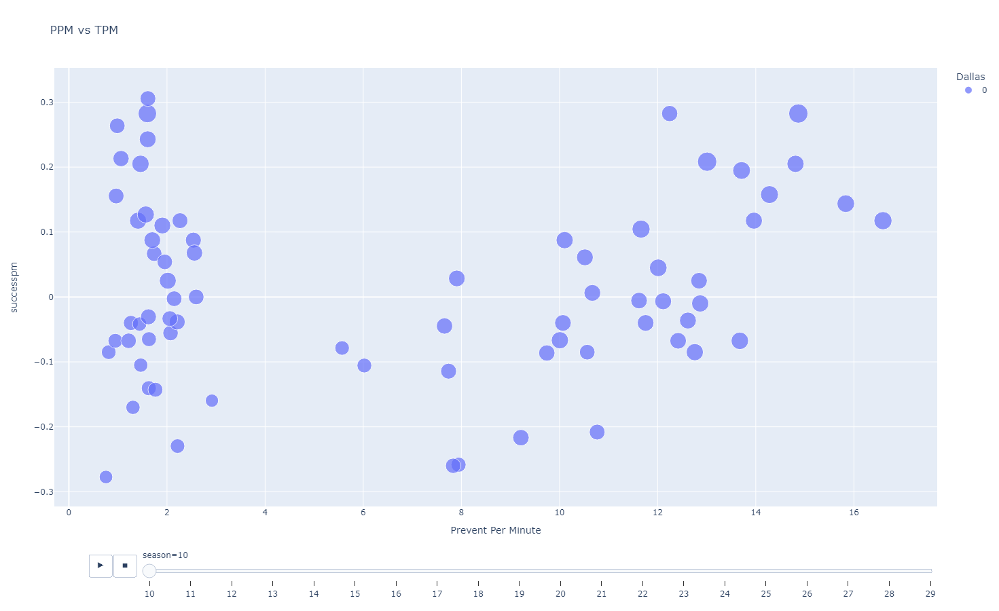

In [10]:
ppm_all = px.scatter(MLTP_master_stats, x = "ppm", y = "successpm",
size = "scorepm", color = "Dallas", animation_frame = "season",
hover_data = ["player"],
labels = {'ppm': 'Prevent Per Minute', 'tpm': 'Tags Per Minute'},
title = 'PPM vs TPM')

ppm_all.update_layout(scene=dict(xaxis=dict(title='Prevent Per Minute'),
yaxis=dict(title='Tags Per Minute')), height = 900)
ppm_all.show()

Looking at the plot for Season 10, which is the default plot that is displayed, we should immediately notice something strange about the shape of the data. There are two main clusters of data points, one of which forms a vertical cluster on the low end of the x axis, indicating that those players' success seems to be independent of their prevent per minute (PPM), while the other cluster of points follows more of a f(x) = cx shape with a weak to moderate positive correlation between PPM and success per minute. Why is this? Players that are offenders will almost always have very low prevent numbers, as they spend very little time in game defending their own flag while attending to their offense duties. Let's look at Hold, a statistic primarily earned by offenders, and confirm that we have a similar pattern.

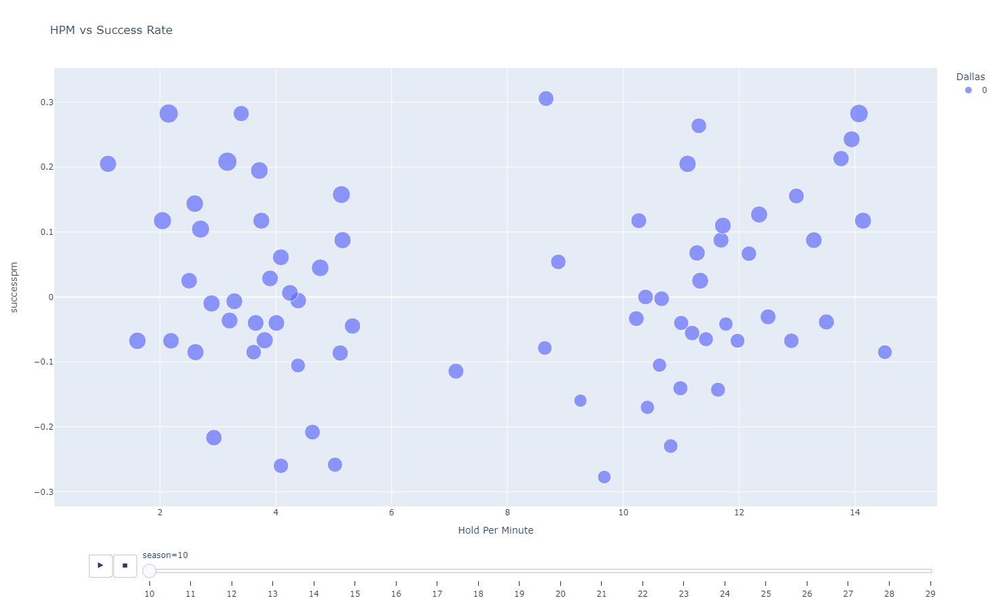

In [11]:
hpm_all = px.scatter(MLTP_master_stats, x = "hpm", y = "successpm",
size = "scorepm", color = "Dallas", animation_frame = "season",
hover_data = ["player"],
labels = {'hpm': 'Hold Per Minute', 'tpm': 'Tags Per Minute'},
title = 'HPM vs Success Rate')

hpm_all.update_layout(scene=dict(xaxis=dict(title='Hold Per Minute'),
yaxis=dict(title='Tags Per Minute')), height = 900)
hpm_all.show()

For Season 10 through 15, we again see this phenomenon of two main clusters of points, with the low values of hold having no correlation (the defenders) and the higher values of hold have a weak positive correlation (the offenders). Interestingly, there appears to be a fairly evenly spread, single cloud of points, with no indication of any correlation between hold and success for Season 16 onwards, which seems indicative that hold has not been an important statistic to consider for quite some time. This seemingly contradicts the widely held community belief that hold is one of the most important statistics to focus on for an offender.

Setting aside this shocking revelation about the importance of Hold for a moment, it becomes clear to us that we need to add some more information to the feature space. First, we need some way to differentiate between offenders and defenders; a successful model will certainly need to treat those as two separate populations if there are multiple features that are only predictive for one of the groups but not the other. While we're at it, we might as well create a binary attribute 'winner' that is 1 if the player has a positive cap differential and 0 otherwise. We will need this response variable both for training and testing the model.

Unfortunately, we don't have access to information on which position each player is playing, and some players will play a mix of both roles throughout a season. The best we can do is assign 'defender' to a player with higher prevent than hold and 'offender' to a player with higher hold than prevent. Irritatingly, sklearn does not handle categorical strings in a graceful manner, so for ease of model building we will just use a '0' for offense and a '1' for defense. 

In [12]:
# Adding in extra features
MLTP_master_stats['position'] = np.where(MLTP_master_stats['ppm'] > MLTP_master_stats['hpm'], 1, 0)
MLTP_master_stats['position'] = MLTP_master_stats['position'].astype('category')

MLTP_master_stats['winner'] = np.where(MLTP_master_stats['successpm'] > 0, 1, 0)
MLTP_master_stats['winner'] = MLTP_master_stats['winner'].astype('category')

MLTP_master_stats

,player,scorepm,minutes,successpm,tpm,poppm,gpm,dropspm,hpm,cpm,...,retinbasepm,quickretpm,savespm,holdagainstpm,Dallas,season,kdr,score_%,position,winner
0,Altiger,4.061111,360,0.025000,0.991667,1.530556,1.408333,1.275000,11.327778,0.100000,...,0.133333,0.111111,0.013889,30.463889,0,10,0.647913,7.100592,0,1
2,Death Pickle,3.947500,400,-0.040000,1.510000,0.775000,0.455000,0.435000,3.652500,0.017500,...,0.472500,0.412500,0.007500,31.052500,0,10,1.948387,3.846154,1,0
3,BigBird,4.200000,400,-0.010000,1.375000,0.710000,0.425000,0.395000,2.890000,0.015000,...,0.405000,0.365000,0.005000,30.040000,0,10,1.936620,3.529412,1,0
4,Vials,3.237500,400,-0.040000,0.715000,1.612500,1.485000,1.355000,11.000000,0.102500,...,0.097500,0.085000,0.007500,31.052500,0,10,0.443411,6.902357,0,0
5,Mr.Gone,3.925000,400,-0.040000,1.392500,1.027500,0.565000,0.530000,4.010000,0.032500,...,0.432500,0.335000,0.007500,31.052500,0,10,1.355231,5.752212,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1300,Messi,3.196000,250,-0.104000,0.764000,1.752000,1.684000,1.532000,10.972000,0.152000,...,0.160000,0.128000,0.020000,29.772000,1,29,0.436073,9.026128,0,0
1301,BoldRoller,3.750000,268,0.070896,0.917910,1.727612,1.473881,1.339552,10.167910,0.126866,...,0.205224,0.227612,0.003731,25.104478,1,29,0.531317,8.607595,0,1
1303,Prime,3.370000,200,0.100000,0.980000,1.150000,0.775000,0.715000,3.665000,0.050000,...,0.290000,0.270000,0.010000,27.620000,1,29,0.852174,6.451613,1,1
1305,flaccid trip,3.887097,248,-0.129032,1.221774,1.120968,0.931452,0.842742,7.483871,0.072581,...,0.395161,0.338710,0.004032,26.661290,1,29,1.089928,7.792208,1,0


Next, let's check the correlation strength between the features to see if there are any highly correlated variables.

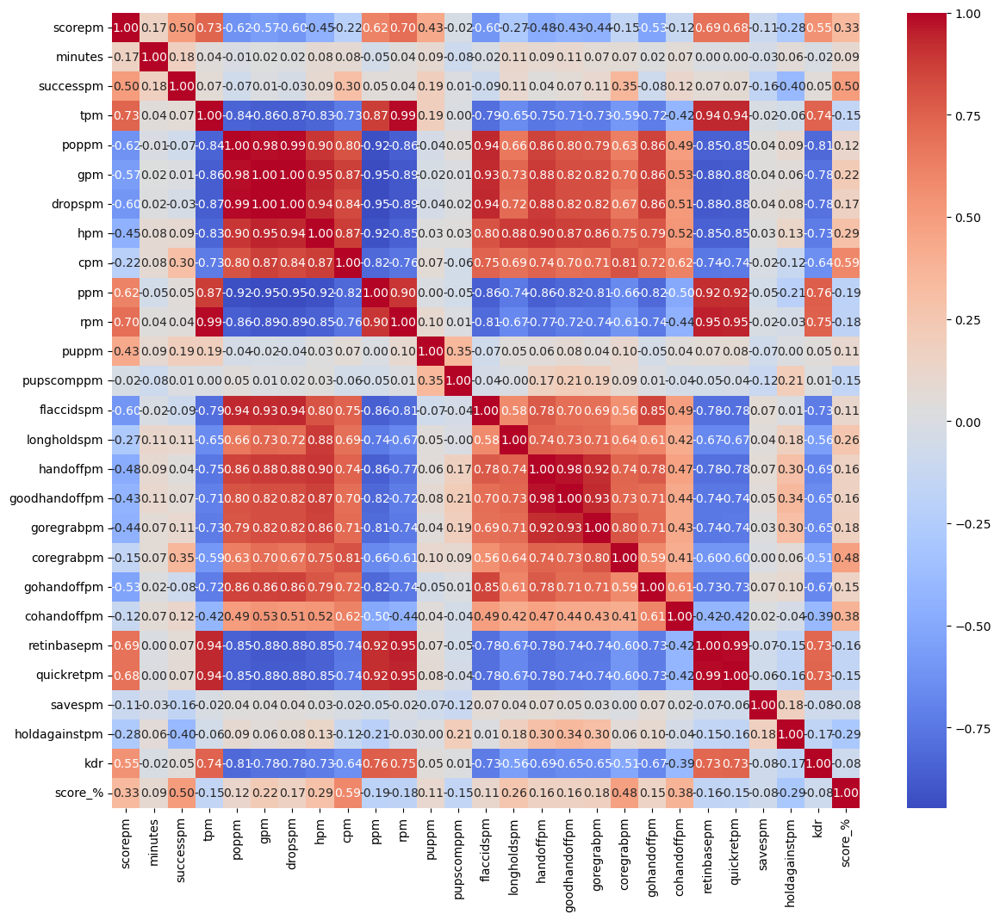

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

corr_matrix = MLTP_master_stats.corr(numeric_only = True)
plt.figure(figsize = (14, 12))
sns.heatmap(corr_matrix, annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.show()

Clearly there are several groups of highly correlated features, but this isn't inherently an issue depending on what kind of deep learning method we use going forward. Let's check for collinearity as well while we're at it.

In [14]:
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Select only the numeric features
numeric_cols = MLTP_master_stats.select_dtypes(include = ['int64', 'float64']).columns
numeric_cols = numeric_cols.delete(numeric_cols.get_loc('successpm'))

print(numeric_cols)

# Create a DataFrame to store the VIF values
MLTP_vif = pd.DataFrame(columns = ['feature', 'VIF'])

# Calculate the VIF for each feature and insert into VIF df
for i, col in enumerate(numeric_cols):
    vif = variance_inflation_factor(MLTP_master_stats[numeric_cols].values, i)
    MLTP_vif.loc[i] = [col, vif]

# View the VIF DataFrame
print(MLTP_vif)

Index(['scorepm', 'minutes', 'tpm', 'poppm', 'gpm', 'dropspm', 'hpm', 'cpm',
       'ppm', 'rpm', 'puppm', 'pupscomppm', 'flaccidspm', 'longholdspm',
       'handoffpm', 'goodhandoffpm', 'goregrabpm', 'coregrabpm', 'gohandoffpm',
       'cohandoffpm', 'retinbasepm', 'quickretpm', 'savespm', 'holdagainstpm',
       'kdr', 'score_%'],
      dtype='object')
          feature           VIF
0         scorepm    496.288716
1         minutes     18.677807
2             tpm    703.645791
3           poppm    682.783695
4             gpm  30697.788394
5         dropspm  26295.206374
6             hpm    612.889955
7             cpm    336.239309
8             ppm     55.421083
9             rpm    567.887786
10          puppm     56.675337
11     pupscomppm    207.667717
12     flaccidspm    110.028657
13    longholdspm     48.572062
14      handoffpm    202.576212
15  goodhandoffpm    147.953609
16     goregrabpm     53.892869
17     coregrabpm     16.656591
18    gohandoffpm     25.944345
19 

Most of the features have a Variance Inflation Factor significantly higher than 5, which is the standard cutoff for excluded features from multilinear regression. If only a few had a high VIF, we could prune those out and use linear modeling methodologies but that is untenable in a situation where only two of the features have a VIF < 5. We will need to use a nonlinear modeling approach that is robust against highly correlated and collinear data. 

Now that we have run through standard operating procedure EDA, let's incorporate the feature selection based on SME knowledge and research results as mentioned earlier. The two main actions we must carry out are cutting down on the feature space dimensionality and seperating the master dataset into two segments, one for players that primarily played defense and the other for players that primarily played offense. Prior exploration saw models struggle somewhat to deal with both types of players lumped together into one population, chiefly due to the fact that we were trying to predict whether a player had a winning season or not, and the tasks that a defender and an offender must focus on to win are very different.

In [15]:
# Remove columns with little value or high collinearity
MLTP_pruned = MLTP_master_stats.drop(columns = ['pupscomppm', 'flaccidspm', 'longholdspm',
       'handoffpm', 'goodhandoffpm', 'goregrabpm', 'coregrabpm', 'gohandoffpm',
       'cohandoffpm', 'retinbasepm', 'quickretpm', 'savespm', 'holdagainstpm'])
MLTP_pruned

,player,scorepm,minutes,successpm,tpm,poppm,gpm,dropspm,hpm,cpm,ppm,rpm,puppm,Dallas,season,kdr,score_%,position,winner
0,Altiger,4.061111,360,0.025000,0.991667,1.530556,1.408333,1.275000,11.327778,0.100000,2.016667,0.708333,0.500000,0,10,0.647913,7.100592,0,1
2,Death Pickle,3.947500,400,-0.040000,1.510000,0.775000,0.455000,0.435000,3.652500,0.017500,11.755000,1.342500,0.290000,0,10,1.948387,3.846154,1,0
3,BigBird,4.200000,400,-0.010000,1.375000,0.710000,0.425000,0.395000,2.890000,0.015000,12.867500,1.197500,0.340000,0,10,1.936620,3.529412,1,0
4,Vials,3.237500,400,-0.040000,0.715000,1.612500,1.485000,1.355000,11.000000,0.102500,1.265000,0.475000,0.295000,0,10,0.443411,6.902357,0,0
5,Mr.Gone,3.925000,400,-0.040000,1.392500,1.027500,0.565000,0.530000,4.010000,0.032500,10.070000,1.260000,0.247500,0,10,1.355231,5.752212,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1300,Messi,3.196000,250,-0.104000,0.764000,1.752000,1.684000,1.532000,10.972000,0.152000,2.576000,0.600000,0.212000,1,29,0.436073,9.026128,0,0
1301,BoldRoller,3.750000,268,0.070896,0.917910,1.727612,1.473881,1.339552,10.167910,0.126866,3.582090,0.671642,0.279851,1,29,0.531317,8.607595,0,1
1303,Prime,3.370000,200,0.100000,0.980000,1.150000,0.775000,0.715000,3.665000,0.050000,11.040000,0.755000,0.230000,1,29,0.852174,6.451613,1,1
1305,flaccid trip,3.887097,248,-0.129032,1.221774,1.120968,0.931452,0.842742,7.483871,0.072581,10.306452,1.028226,0.181452,1,29,1.089928,7.792208,1,0


The columns 'Dallas' and 'winner' were nice to have, sepecially during the EDA stage, but will offer little intrinsic value in the way of modeling anomaly detection, so we can drop those before we begin modeling and add them back in later if necessary. We can also remove 'minutes', as we have already created the necessary per minute statistics and no longer have use for it.

In [16]:
#MLTP_pruned = MLTP_pruned.drop(columns = ['winner', 'minutes'])
MLTP_pruned

,player,scorepm,minutes,successpm,tpm,poppm,gpm,dropspm,hpm,cpm,ppm,rpm,puppm,Dallas,season,kdr,score_%,position,winner
0,Altiger,4.061111,360,0.025000,0.991667,1.530556,1.408333,1.275000,11.327778,0.100000,2.016667,0.708333,0.500000,0,10,0.647913,7.100592,0,1
2,Death Pickle,3.947500,400,-0.040000,1.510000,0.775000,0.455000,0.435000,3.652500,0.017500,11.755000,1.342500,0.290000,0,10,1.948387,3.846154,1,0
3,BigBird,4.200000,400,-0.010000,1.375000,0.710000,0.425000,0.395000,2.890000,0.015000,12.867500,1.197500,0.340000,0,10,1.936620,3.529412,1,0
4,Vials,3.237500,400,-0.040000,0.715000,1.612500,1.485000,1.355000,11.000000,0.102500,1.265000,0.475000,0.295000,0,10,0.443411,6.902357,0,0
5,Mr.Gone,3.925000,400,-0.040000,1.392500,1.027500,0.565000,0.530000,4.010000,0.032500,10.070000,1.260000,0.247500,0,10,1.355231,5.752212,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1300,Messi,3.196000,250,-0.104000,0.764000,1.752000,1.684000,1.532000,10.972000,0.152000,2.576000,0.600000,0.212000,1,29,0.436073,9.026128,0,0
1301,BoldRoller,3.750000,268,0.070896,0.917910,1.727612,1.473881,1.339552,10.167910,0.126866,3.582090,0.671642,0.279851,1,29,0.531317,8.607595,0,1
1303,Prime,3.370000,200,0.100000,0.980000,1.150000,0.775000,0.715000,3.665000,0.050000,11.040000,0.755000,0.230000,1,29,0.852174,6.451613,1,1
1305,flaccid trip,3.887097,248,-0.129032,1.221774,1.120968,0.931452,0.842742,7.483871,0.072581,10.306452,1.028226,0.181452,1,29,1.089928,7.792208,1,0


Now it's time to perform our positional segmentation of the data.

In [17]:
# Segment creation
MLTP_D = MLTP_pruned[MLTP_pruned['position'] == 1]
MLTP_D = MLTP_D.reset_index(drop=True)

# Position column irrelevant now
MLTP_D = MLTP_D.drop(columns = ['position'])
MLTP_D

,player,scorepm,minutes,successpm,tpm,poppm,gpm,dropspm,hpm,cpm,ppm,rpm,puppm,Dallas,season,kdr,score_%,winner
0,Death Pickle,3.947500,400,-0.040000,1.510000,0.775000,0.455000,0.435000,3.652500,0.017500,11.755000,1.342500,0.290000,0,10,1.948387,3.846154,0
1,BigBird,4.200000,400,-0.010000,1.375000,0.710000,0.425000,0.395000,2.890000,0.015000,12.867500,1.197500,0.340000,0,10,1.936620,3.529412,0
2,Mr.Gone,3.925000,400,-0.040000,1.392500,1.027500,0.565000,0.530000,4.010000,0.032500,10.070000,1.260000,0.247500,0,10,1.355231,5.752212,0
3,Sundown,3.883008,359,-0.005571,1.295265,0.832869,0.498607,0.467967,4.387187,0.027855,11.621170,1.125348,0.256267,0,10,1.555184,5.586592,0
4,yank,3.994186,344,0.061047,1.223837,0.840116,0.526163,0.470930,4.087209,0.046512,10.517442,1.069767,0.319767,0,10,1.456747,8.839779,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
472,NEB.,4.545977,348,0.112069,1.551724,1.106322,0.836207,0.741379,5.767241,0.089080,12.089080,1.244253,0.278736,1,29,1.402597,10.652921,1
473,Xile,3.988571,350,-0.120000,1.294286,1.122857,0.788571,0.697143,4.811429,0.080000,12.908571,1.125714,0.220000,1,29,1.152672,10.144928,0
474,Armbranch,3.794286,350,-0.120000,1.397143,0.854286,0.571429,0.540000,3.305714,0.028571,13.531429,1.225714,0.231429,1,29,1.635452,5.000000,0
475,Prime,3.370000,200,0.100000,0.980000,1.150000,0.775000,0.715000,3.665000,0.050000,11.040000,0.755000,0.230000,1,29,0.852174,6.451613,1


In [18]:
# Segment creation
MLTP_O = MLTP_pruned[MLTP_pruned['position'] == 0]
MLTP_O = MLTP_O.reset_index(drop=True)

# Position column irrelevant now
MLTP_O = MLTP_O.drop(columns = ['position'])
MLTP_O

,player,scorepm,minutes,successpm,tpm,poppm,gpm,dropspm,hpm,cpm,ppm,rpm,puppm,Dallas,season,kdr,score_%,winner
0,Altiger,4.061111,360,0.025000,0.991667,1.530556,1.408333,1.275000,11.327778,0.100000,2.016667,0.708333,0.500000,0,10,0.647913,7.100592,1
1,Vials,3.237500,400,-0.040000,0.715000,1.612500,1.485000,1.355000,11.000000,0.102500,1.265000,0.475000,0.295000,0,10,0.443411,6.902357,0
2,dywz,3.472973,370,-0.002703,0.616216,1.605405,1.416216,1.286486,10.662162,0.124324,2.145946,0.483784,0.245946,0,10,0.383838,8.778626,0
3,ooo killem,3.405556,360,0.066667,0.808333,1.569444,1.405556,1.305556,12.169444,0.091667,1.738889,0.588889,0.336111,0,10,0.515044,6.521739,1
4,bad,3.547500,400,0.117500,0.842500,1.415000,1.277500,1.145000,10.267500,0.115000,2.265000,0.605000,0.340000,0,10,0.595406,9.001957,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
434,2P1S,3.669540,348,0.112069,0.853448,1.491379,1.373563,1.209770,9.169540,0.146552,3.916667,0.603448,0.247126,1,29,0.572254,10.669456,1
435,CoolCat,2.765714,350,-0.120000,0.768571,1.614286,1.442857,1.328571,8.794286,0.082857,3.091429,0.542857,0.222857,1,29,0.476106,5.742574,0
436,Messi,3.196000,250,-0.104000,0.764000,1.752000,1.684000,1.532000,10.972000,0.152000,2.576000,0.600000,0.212000,1,29,0.436073,9.026128,0
437,BoldRoller,3.750000,268,0.070896,0.917910,1.727612,1.473881,1.339552,10.167910,0.126866,3.582090,0.671642,0.279851,1,29,0.531317,8.607595,1


Let's take another look at our original graphs now that we have our two distinct populations separated from each other and the fluff columns removed. While we're at it, let's spruce up the aesthetic appeal as well by changing the color of the points to represent the success rate of the players instead of whether or not the games were played on Dallas servers. Adjusting the axes to ensure all of the points fit completely on the graph will improve the quality as well.

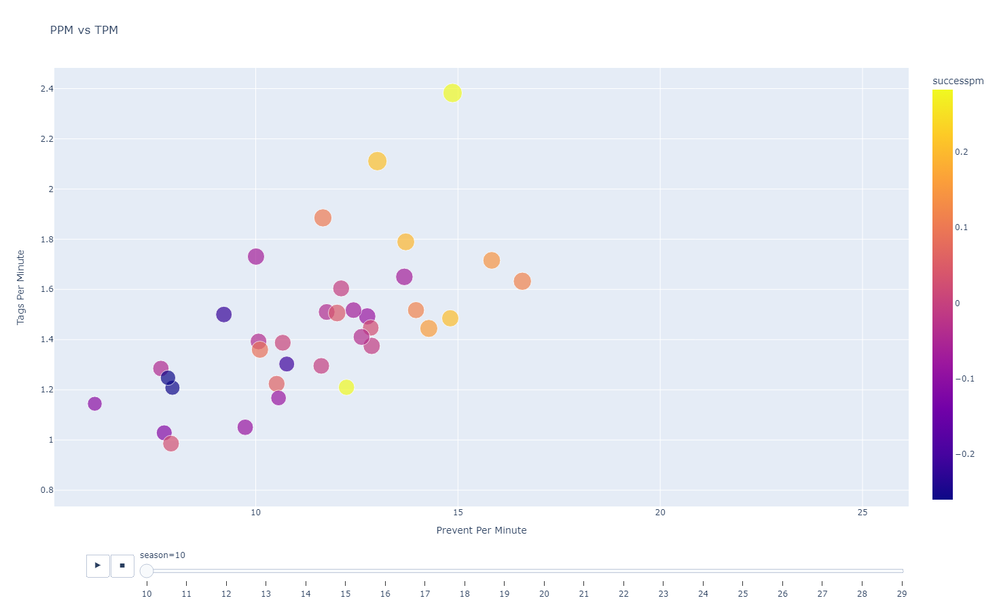

In [19]:
ppm_tpm_D = px.scatter(MLTP_D, x = "ppm", y = "tpm",
size = "scorepm", color = "successpm", animation_frame = "season",
hover_data = ["player"],
labels = {'ppm': 'Prevent Per Minute', 'tpm': 'Tags Per Minute'},
title = 'PPM vs TPM')

ppm_tpm_D.update_xaxes(range = [MLTP_D['ppm'].min() - 1, MLTP_D['ppm'].max() + 1])
ppm_tpm_D.update_yaxes(range = [MLTP_D['tpm'].min() - 0.1, MLTP_D['tpm'].max() + 0.1])

ppm_tpm_D.update_layout(scene=dict(xaxis=dict(title='Prevent Per Minute'),
yaxis=dict(title='Tags Per Minute')), height = 900)
ppm_tpm_D.show()

Let's zoom out from our more granular season view and take a gander at the bigger picture by combining the observations from each season into only two slices, Dallas vs no Dallas servers.

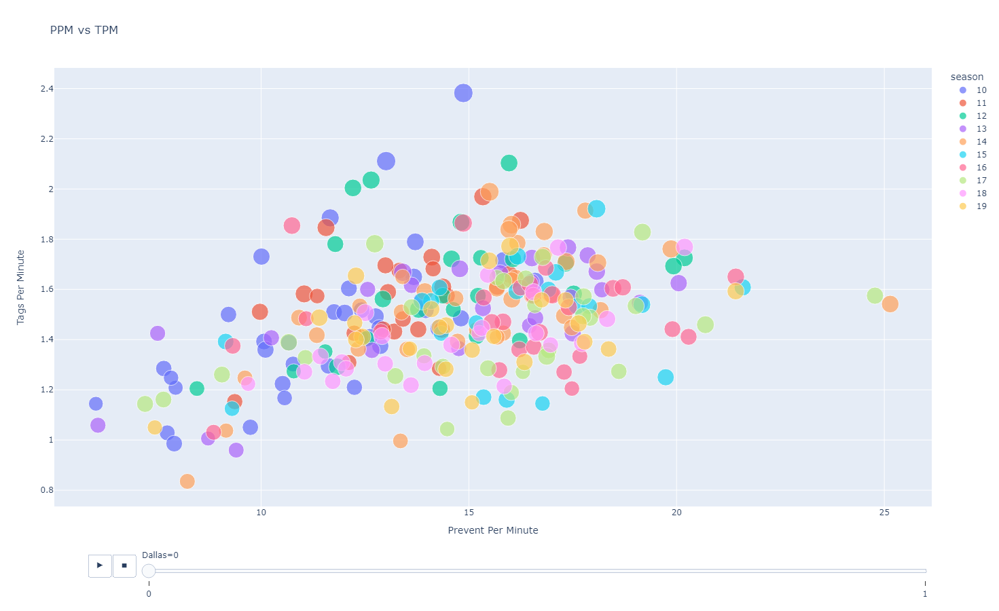

In [20]:
ppm_tpm_D_all = px.scatter(MLTP_D, x = "ppm", y = "tpm",
size = "scorepm", color = "season", animation_frame = "Dallas",
hover_data = ["player"],
labels = {'ppm': 'Prevent Per Minute', 'tpm': 'Tags Per Minute'},
title = 'PPM vs TPM')

ppm_tpm_D_all.update_xaxes(range = [MLTP_D['ppm'].min() - 1, MLTP_D['ppm'].max() + 1])
ppm_tpm_D_all.update_yaxes(range = [MLTP_D['tpm'].min() - 0.1, MLTP_D['tpm'].max() + 0.1])

ppm_tpm_D_all.update_layout(scene=dict(xaxis=dict(title='Prevent Per Minute'),
yaxis=dict(title='Tags Per Minute')), height = 900)
ppm_tpm_D_all.show()

Interestingly, the prevent numbers seem to have shrunk down over time. There are a handful of data points, about a dozen, crossing the 20 PPM barrier in the seasons which were played on home servers and even a few points all the way up near 25 PPM. Yet for the Dallas seasons, only twice did a player achieve 20 PPM. There is a similar phenomenon present with the tag numbers; a decent number of players used to hit around or above 2 tags per minute, yet only once did a player achieve that on Dallas servers. Let's move on to the revamped offense chart.

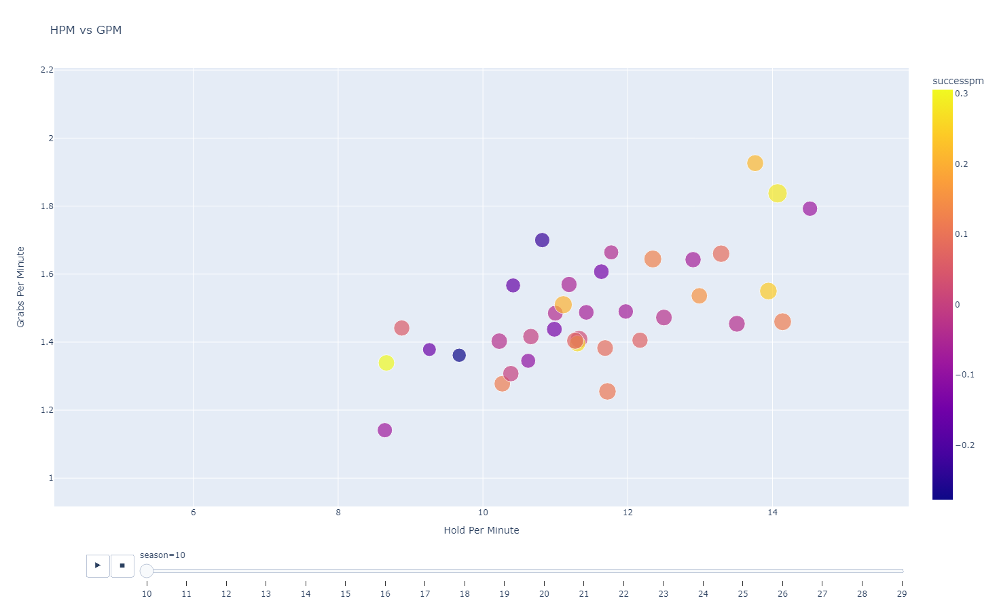

In [21]:
hpm_O = px.scatter(MLTP_O, x = "hpm", y = "gpm",
size = "scorepm", color = "successpm", animation_frame = "season",
hover_data = ["player"],
labels = {'hpm': 'Hold Per Minute', 'gpm': 'Grabs Per Minute'},
title = 'HPM vs GPM')

hpm_O.update_xaxes(range = [MLTP_O['hpm'].min() - 1, MLTP_O['hpm'].max() + 1])
hpm_O.update_yaxes(range = [MLTP_O['gpm'].min() - 0.1, MLTP_O['gpm'].max() + 0.1])

hpm_O.update_layout(scene=dict(xaxis=dict(title='Hold Per Minute'),
yaxis=dict(title='Grabs Per Minute')), height = 900)
hpm_O.show()

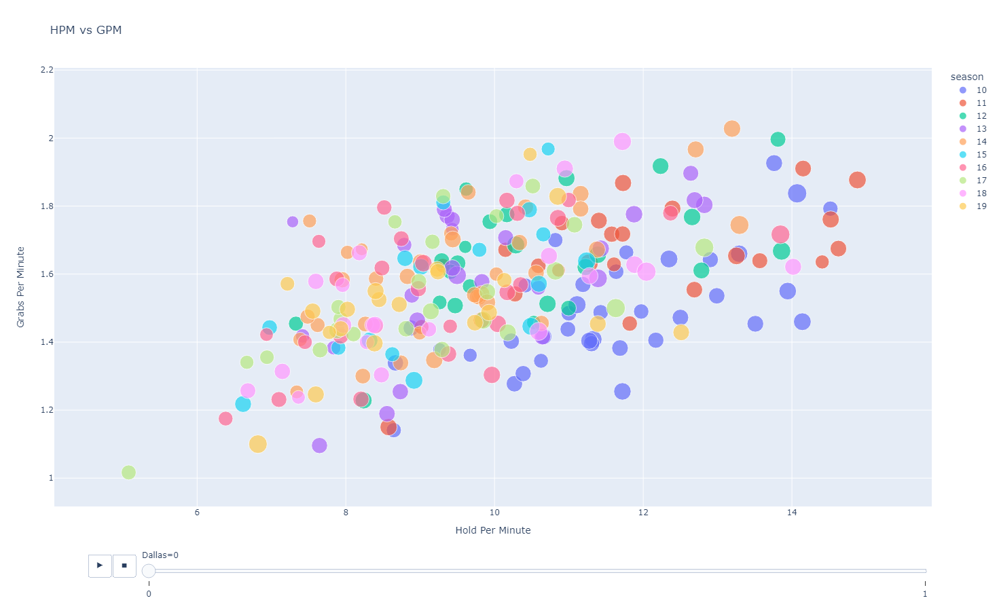

In [22]:
hpm_gpm_O_all = px.scatter(MLTP_O, x = "hpm", y = "gpm",
size = "scorepm", color = "season", animation_frame = "Dallas",
hover_data = ["player"],
labels = {'hpm': 'Hold Per Minute', 'gpm': 'Grabs Per Minute'},
title = 'HPM vs GPM')

hpm_gpm_O_all.update_xaxes(range = [MLTP_O['hpm'].min() - 1, MLTP_O['hpm'].max() + 1])
hpm_gpm_O_all.update_yaxes(range = [MLTP_O['gpm'].min() - 0.1, MLTP_O['gpm'].max() + 0.1])

hpm_gpm_O_all.update_layout(scene=dict(xaxis=dict(title='Hold Per Minute'),
yaxis=dict(title='Grabs Per Minute')), height = 900)
hpm_gpm_O_all.show()

One might intuitively expect that if players were getting less prevent (meaning their flag was taken) and getting less tags (tagging a flag carrier will send the flag back to the base), that there was more flag grabbing occuring and offenders were getting better at evading defenders, causing their grabs and hold to rise. Shockingly, both hold and grabs have been on the decline over the seasons as well.

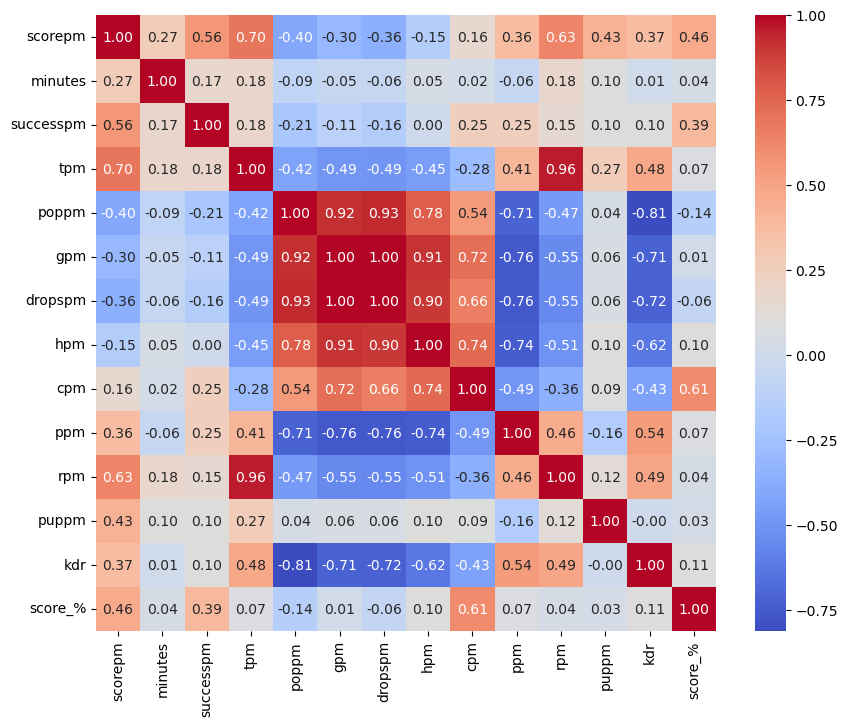

In [23]:
D_corr_matrix = MLTP_D.corr(numeric_only = True)
plt.figure(figsize=(10, 8))
sns.heatmap(D_corr_matrix, annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.show()

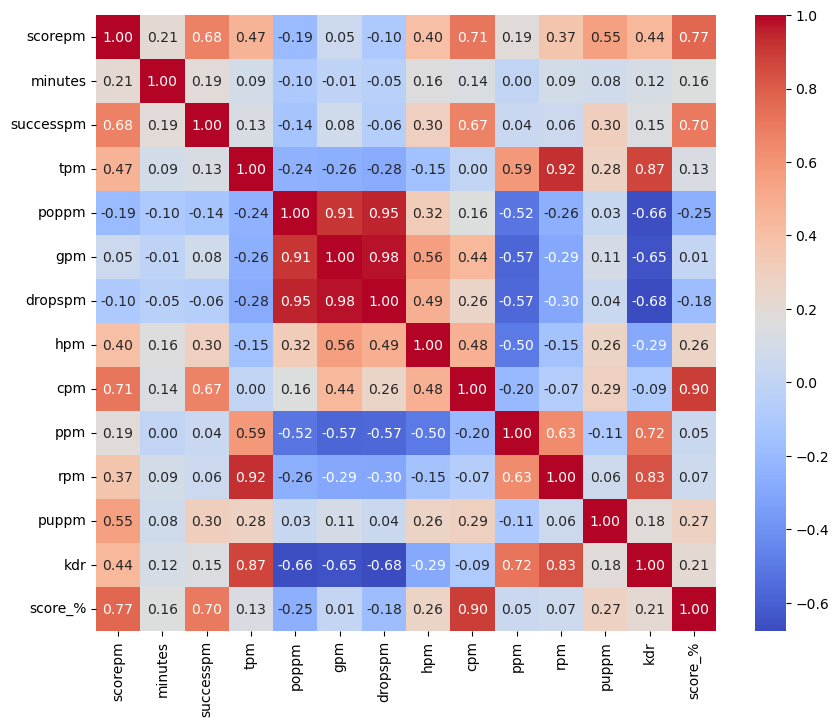

In [24]:
O_corr_matrix = MLTP_O.corr(numeric_only = True)
plt.figure(figsize = (10, 8))
sns.heatmap(O_corr_matrix, annot = True, fmt = '.2f', cmap = 'coolwarm')
plt.show()

Checking out our new correlation matrices shows that we have removed a nontrivial portion of the highly correlated features, although some of them do remain. We shall elect not to prune any more of them at present based on our SME's understanding of the nuances for each statistic. 

In [25]:
D_numeric_cols = MLTP_D.select_dtypes(include = ['int64', 'float64']).columns
print(D_numeric_cols)

D_numeric_cols = D_numeric_cols.delete(D_numeric_cols.get_loc('successpm'))

print(D_numeric_cols)

# Create a DataFrame to store the VIF values
D_vif = pd.DataFrame(columns = ['feature', 'VIF'])

# Calculate the VIF for each feature and insert into VIF df
for i, col in enumerate(D_numeric_cols):
    vif = variance_inflation_factor(MLTP_D[D_numeric_cols].values, i)
    D_vif.loc[i] = [col, vif]

# View the VIF DataFrame
print(D_vif)

Index(['scorepm', 'minutes', 'successpm', 'tpm', 'poppm', 'gpm', 'dropspm',
       'hpm', 'cpm', 'ppm', 'rpm', 'puppm', 'kdr', 'score_%'],
      dtype='object')
Index(['scorepm', 'minutes', 'tpm', 'poppm', 'gpm', 'dropspm', 'hpm', 'cpm',
       'ppm', 'rpm', 'puppm', 'kdr', 'score_%'],
      dtype='object')
    feature           VIF
0   scorepm    644.270605
1   minutes     18.414088
2       tpm    867.561850
3     poppm    214.705637
4       gpm  13680.950095
5   dropspm  12007.164352
6       hpm     74.745896
7       cpm    125.119818
8       ppm     75.326962
9       rpm    716.836557
10    puppm     49.159213
11      kdr     11.684641
12  score_%     26.708422


In [26]:
O_numeric_cols = MLTP_O.select_dtypes(include = ['int64', 'float64']).columns
print(O_numeric_cols)

O_numeric_cols = O_numeric_cols.delete(O_numeric_cols.get_loc('successpm'))

print(O_numeric_cols)

# Create a DataFrame to store the VIF values
O_vif = pd.DataFrame(columns = ['feature', 'VIF'])

# Calculate the VIF for each feature and insert into VIF df
for i, col in enumerate(O_numeric_cols):
    vif = variance_inflation_factor(MLTP_O[O_numeric_cols].values, i)
    O_vif.loc[i] = [col, vif]

# View the VIF DataFrame
print(O_vif)

Index(['scorepm', 'minutes', 'successpm', 'tpm', 'poppm', 'gpm', 'dropspm',
       'hpm', 'cpm', 'ppm', 'rpm', 'puppm', 'kdr', 'score_%'],
      dtype='object')
Index(['scorepm', 'minutes', 'tpm', 'poppm', 'gpm', 'dropspm', 'hpm', 'cpm',
       'ppm', 'rpm', 'puppm', 'kdr', 'score_%'],
      dtype='object')
    feature           VIF
0   scorepm    401.697746
1   minutes     19.565738
2       tpm    935.470304
3     poppm   1341.242277
4       gpm  42642.425468
5   dropspm  33856.421586
6       hpm     96.206855
7       cpm   1020.179825
8       ppm     24.289692
9       rpm    256.581345
10    puppm     58.902417
11      kdr    684.795242
12  score_%    607.252834


Tragically, the Variance Inflation Factors are quite high for both populations even after the dimensionality reduction, so we will have to resort to unsupervised learning techniques that are robust against collinearity.

**Modeling + Results + Analysis**

There are several different deep learning architectures that are suitable for tasks involving binary classification with non-linear data. Several examples of these techniques are Long Short-Term Networks (LSTM), Recurrent Neural Networks (RNN), Convolutional Neural Networks (CNN), and Multilayer Perceptron (MLP). Investigating each of these in turn will allow us to make the optimal choice for our model architecture for our TagPro winners and losers classification.

LSTM is a special class of technique within the bigger family of RNNs, and thus it is no surprise they are both aligned towards working with the same kinds of data. Both of these techniques are preferential for sequential data, time series, and natural language processing (NLP); investigating a specific player's play over the seasons would be an application of the data that could necessitate an RNN that is able to grasp the intricacies of long-term patterns in the data. Since we are treating each season for each player as a single data point and looking at all players rather than following the trajectory of a single player, we can explore other options to look for a better fit.

Convolutional Neural Networks are an excellent and powerful tool in the astute data scientist's deep learning repertoire for binary or multiclass classification. However, CNNs are designed to function best with image classification specifically; since we aren't dealing with images for this task, CNNs are not the best tool for the job either.

Last but certainly not least we go back to basics with our friend, the humble Multilayer Perceptron. While some may look down on Multilayer Perceptrons for being relatively simple compared to some of the newer architectures like Generative Adversarial Networks, MLPs are quite good at binary classification tasks and can handle data that is not linearly separable, so this will be our weapon of choice for the upcoming battle.

In [27]:
from sklearn.model_selection import train_test_split

# X features y target
X = MLTP_O.drop(columns = ['winner', 'player', 'scorepm'])
y = MLTP_O['winner']  

# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1234)

# Check the shapes
print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_test shape:', X_test.shape)
print('y_test shape:', y_test.shape)

X_train shape: (351, 15)
y_train shape: (351,)
X_test shape: (88, 15)
y_test shape: (88,)


An MLP is a type of fully connected, feedforward artifical neural network comprised of an input layer, some nozero number of hidden layers, and then an output layer. Each of the layers, with the exclusion of the first layer (input layer), acts similarly to how a neuron in an animal brain does (action potential neuron firing), using a nonlinear activation function to take the information it received as input and transform it into some output. Common activation function historically have been sigmoid and hyperbolic tangent, but there has recently been a shift towards employing Rectified Linear Unit (ReLU) to mitigate the impact of vanishing gradient issues present in other activation functions.

Let's start off with segmenting the offender population into an 80/20 train/test split and build the simplest MLP possible, with just a single hidden layer, ReLU activation functions for the first two layers and then a sigmoid activation function for the final layer, as we would like a final output with a range that maps between 0 and 1.

**Model 1: Simple MLP**

In [28]:
from keras.models import Sequential
from keras.layers import Dense
from keras.callbacks import EarlyStopping

# Define the MLP model
simple_model = Sequential()
simple_model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model.add(Dense(32, activation='relu'))
simple_model.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history = simple_model.fit(X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

Epoch 1/20
11/11 [==============================] - 1s 12ms/step - loss: 3.9337 - accuracy: 0.4701 - val_loss: 2.9696 - val_accuracy: 0.4318
Epoch 2/20
11/11 [==============================] - 0s 2ms/step - loss: 1.8529 - accuracy: 0.4986 - val_loss: 1.1102 - val_accuracy: 0.5114
Epoch 3/20
11/11 [==============================] - 0s 2ms/step - loss: 1.3922 - accuracy: 0.4501 - val_loss: 1.1604 - val_accuracy: 0.4545
Epoch 4/20
11/11 [==============================] - 0s 2ms/step - loss: 1.2118 - accuracy: 0.4302 - val_loss: 1.0671 - val_accuracy: 0.5000
Epoch 5/20
11/11 [==============================] - 0s 2ms/step - loss: 1.0965 - accuracy: 0.4530 - val_loss: 0.9845 - val_accuracy: 0.5000
Epoch 6/20
11/11 [==============================] - 0s 2ms/step - loss: 1.0255 - accuracy: 0.4444 - val_loss: 1.0262 - val_accuracy: 0.4886
Epoch 7/20
11/11 [==============================] - 0s 2ms/step - loss: 0.9824 - accuracy: 0.4587 - val_loss: 0.9202 - val_accuracy: 0.5000
Epoch 8/20
11/11 [=

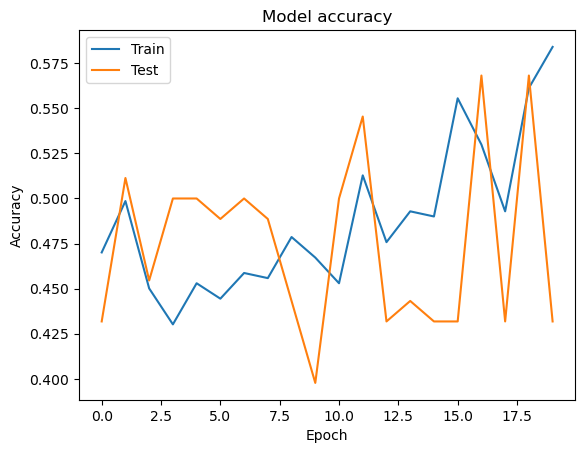

In [29]:
# Plot the accuracy over time
plt.plot(simple_history.history['accuracy'])
plt.plot(simple_history.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

After running for 20 epochs and displaying the training and testing accuracy results, the preliminary numbers are not quite up to snuff. Although the training accuracy was up around 65%, our testing accuracy was lower than 50%, which means guessing randomly would have been a better model. We are going to need some serious hyperparameter tuning to overcome the current status of our MLP results. Additionally, the curves for both test and train are very choppy, suggesting that we either have a suboptimal model architecture, our data is quite noisy, or there weren't enough epochs in the training phase. First, let's try increasing the number of epochs to see if additional training can mitigate either the choppiness or the accuracy situation.

In [30]:
# Define the MLP model
simple_model_100 = Sequential()
simple_model_100.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model_100.add(Dense(32, activation='relu'))
simple_model_100.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model_100.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history_100 = simple_model_100.fit(X_train, y_train, epochs=100, batch_size=32, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model_100.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

Epoch 1/100
11/11 [==============================] - 0s 10ms/step - loss: 2.6890 - accuracy: 0.4672 - val_loss: 1.9423 - val_accuracy: 0.4205
Epoch 2/100
11/11 [==============================] - 0s 2ms/step - loss: 1.3687 - accuracy: 0.4758 - val_loss: 0.7925 - val_accuracy: 0.5114
Epoch 3/100
11/11 [==============================] - 0s 2ms/step - loss: 0.8641 - accuracy: 0.4387 - val_loss: 0.8053 - val_accuracy: 0.3977
Epoch 4/100
11/11 [==============================] - 0s 2ms/step - loss: 0.7900 - accuracy: 0.4416 - val_loss: 0.8365 - val_accuracy: 0.4318
Epoch 5/100
11/11 [==============================] - 0s 2ms/step - loss: 0.7809 - accuracy: 0.4786 - val_loss: 0.8384 - val_accuracy: 0.4091
Epoch 6/100
11/11 [==============================] - 0s 2ms/step - loss: 0.7943 - accuracy: 0.5157 - val_loss: 0.7892 - val_accuracy: 0.4432
Epoch 7/100
11/11 [==============================] - 0s 2ms/step - loss: 0.7511 - accuracy: 0.4530 - val_loss: 0.7835 - val_accuracy: 0.4545
Epoch 8/100


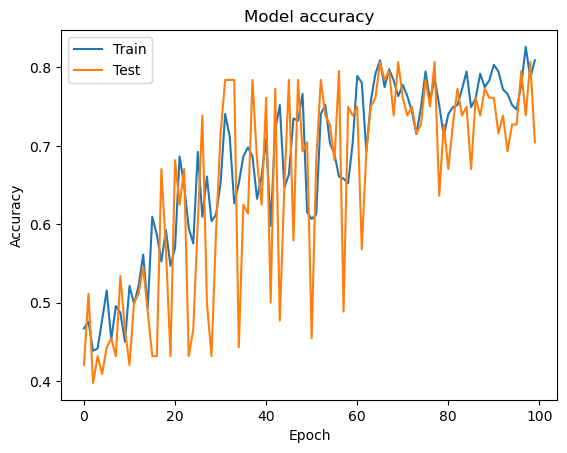

In [31]:
# Plot the accuracy over time
plt.plot(simple_history_100.history['accuracy'])
plt.plot(simple_history_100.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

After increasing the epochs to 100, we already see a remarkable difference in performance. The testing and the training accuracy are both around 75% now out at 100 epochs, and while the curves aren't exactly smooth yet, they are significantly less rough than in the iteration with only 20 epochs. Let's try upping the epochs again, since it doesn't look like we are having overfitting issues yet.

In [32]:
# Define the MLP model
simple_model_500 = Sequential()
simple_model_500.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model_500.add(Dense(32, activation='relu'))
simple_model_500.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model_500.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history_500 = simple_model_500.fit(X_train, y_train, epochs=500, batch_size=32, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model_500.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

Epoch 1/500
11/11 [==============================] - 0s 10ms/step - loss: 5.4464 - accuracy: 0.4701 - val_loss: 2.0880 - val_accuracy: 0.5682
Epoch 2/500
11/11 [==============================] - 0s 2ms/step - loss: 1.2624 - accuracy: 0.5470 - val_loss: 0.6582 - val_accuracy: 0.6250
Epoch 3/500
11/11 [==============================] - 0s 2ms/step - loss: 0.8169 - accuracy: 0.5043 - val_loss: 0.6601 - val_accuracy: 0.6364
Epoch 4/500
11/11 [==============================] - 0s 2ms/step - loss: 0.6937 - accuracy: 0.5527 - val_loss: 0.6557 - val_accuracy: 0.6705
Epoch 5/500
11/11 [==============================] - 0s 2ms/step - loss: 0.6690 - accuracy: 0.5755 - val_loss: 0.6428 - val_accuracy: 0.6591
Epoch 6/500
11/11 [==============================] - 0s 2ms/step - loss: 0.7020 - accuracy: 0.5812 - val_loss: 0.6644 - val_accuracy: 0.5682
Epoch 7/500
11/11 [==============================] - 0s 2ms/step - loss: 0.6636 - accuracy: 0.6097 - val_loss: 0.6441 - val_accuracy: 0.5795
Epoch 8/500


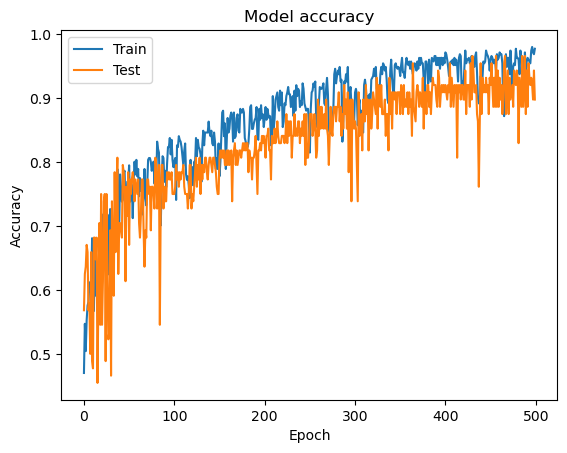

In [33]:
# Plot the accuracy over time
plt.plot(simple_history_500.history['accuracy'])
plt.plot(simple_history_500.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

The curve choppiness continues to persist, but the training and testing accuracy both continue to improve in tandem, putting up around 90% accuracy each. The beauty of using such a simple model is that we can train hundreds or thousands of epochs in under a minute with just a CPU, whereas a more complicated GAN could take hours to train just a hundred epochs even with TPUs. Let's try bumping the epochs up one last time, to 1000.

In [34]:
# Define the MLP model
simple_model_1000 = Sequential()
simple_model_1000.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model_1000.add(Dense(32, activation='relu'))
simple_model_1000.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model_1000.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history_1000 = simple_model_1000.fit(X_train, y_train, epochs=1000, batch_size=32, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model_1000.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

Epoch 1/1000
11/11 [==============================] - 0s 9ms/step - loss: 7.0442 - accuracy: 0.4957 - val_loss: 6.3125 - val_accuracy: 0.4318
Epoch 2/1000
11/11 [==============================] - 0s 2ms/step - loss: 3.2502 - accuracy: 0.5043 - val_loss: 2.0943 - val_accuracy: 0.5341
Epoch 3/1000
11/11 [==============================] - 0s 2ms/step - loss: 1.6742 - accuracy: 0.4843 - val_loss: 1.0144 - val_accuracy: 0.5227
Epoch 4/1000
11/11 [==============================] - 0s 2ms/step - loss: 1.0354 - accuracy: 0.5185 - val_loss: 1.0045 - val_accuracy: 0.5341
Epoch 5/1000
11/11 [==============================] - 0s 2ms/step - loss: 0.9131 - accuracy: 0.5071 - val_loss: 1.0407 - val_accuracy: 0.5000
Epoch 6/1000
11/11 [==============================] - 0s 2ms/step - loss: 0.8423 - accuracy: 0.5527 - val_loss: 0.9502 - val_accuracy: 0.5000
Epoch 7/1000
11/11 [==============================] - 0s 2ms/step - loss: 0.7674 - accuracy: 0.5670 - val_loss: 0.7969 - val_accuracy: 0.5000
Epoch 

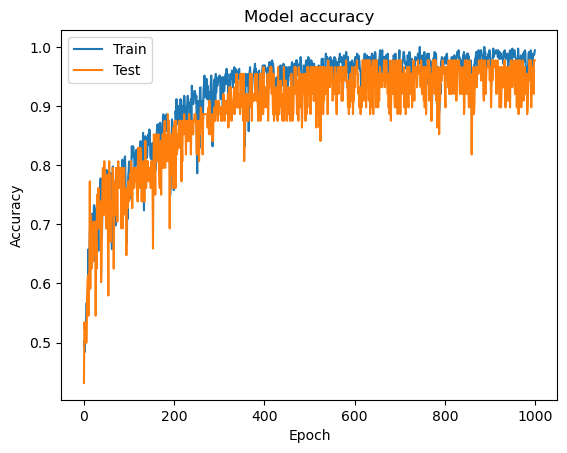

In [35]:
# Plot the accuracy over time
plt.plot(simple_history_1000.history['accuracy'])
plt.plot(simple_history_1000.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

Once again, the accuracy for both train and test have increased,coming in at over 95%, yet the choppiness still stubbornly remains. We do see that the accuracy increases seem to level off around ~750 epochs, so let's leave epochs alone for now and try tuning a different hyperparameter, batch size.

In [36]:
# Define the MLP model
simple_model_16 = Sequential()
simple_model_16.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model_16.add(Dense(32, activation='relu'))
simple_model_16.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model_16.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history_16 = simple_model_16.fit(X_train, y_train, epochs=800, batch_size=16, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model_16.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

Epoch 1/800
22/22 [==============================] - 0s 6ms/step - loss: 1.1638 - accuracy: 0.5214 - val_loss: 0.7800 - val_accuracy: 0.5795
Epoch 2/800
22/22 [==============================] - 0s 2ms/step - loss: 0.7785 - accuracy: 0.5385 - val_loss: 0.6522 - val_accuracy: 0.5795
Epoch 3/800
22/22 [==============================] - 0s 2ms/step - loss: 0.7415 - accuracy: 0.5698 - val_loss: 0.6335 - val_accuracy: 0.6250
Epoch 4/800
22/22 [==============================] - 0s 2ms/step - loss: 0.7325 - accuracy: 0.5670 - val_loss: 0.8079 - val_accuracy: 0.5682
Epoch 5/800
22/22 [==============================] - 0s 2ms/step - loss: 0.6638 - accuracy: 0.6211 - val_loss: 0.6742 - val_accuracy: 0.5455
Epoch 6/800
22/22 [==============================] - 0s 1ms/step - loss: 0.6712 - accuracy: 0.5840 - val_loss: 0.5830 - val_accuracy: 0.6818
Epoch 7/800
22/22 [==============================] - 0s 2ms/step - loss: 0.6032 - accuracy: 0.6695 - val_loss: 0.5739 - val_accuracy: 0.7273
Epoch 8/800
2

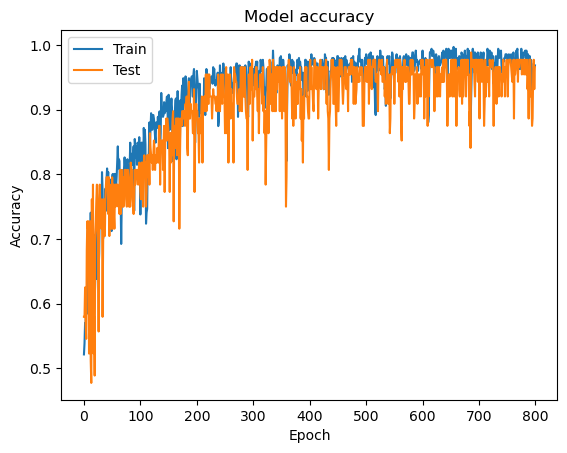

In [37]:
plt.plot(simple_history_16.history['accuracy'])
plt.plot(simple_history_16.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

With our batch size set to 16, we seem to get to the same ending accuracies as when batch size was 32, but in far fewer epochs, leveling off around 400 epochs at 95%+ instead of 750 epochs. Let's try more values.

In [38]:
# Define the MLP model
simple_model_8 = Sequential()
simple_model_8.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model_8.add(Dense(32, activation='relu'))
simple_model_8.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model_8.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history_8 = simple_model_8.fit(X_train, y_train, epochs=500, batch_size=8, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model_8.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

Epoch 1/500
44/44 [==============================] - 0s 3ms/step - loss: 5.5967 - accuracy: 0.4986 - val_loss: 1.7066 - val_accuracy: 0.4432
Epoch 2/500
44/44 [==============================] - 0s 954us/step - loss: 1.1870 - accuracy: 0.4701 - val_loss: 1.0671 - val_accuracy: 0.4886
Epoch 3/500
44/44 [==============================] - 0s 977us/step - loss: 1.0343 - accuracy: 0.4558 - val_loss: 1.0695 - val_accuracy: 0.4432
Epoch 4/500
44/44 [==============================] - 0s 982us/step - loss: 1.0344 - accuracy: 0.5328 - val_loss: 0.9352 - val_accuracy: 0.5568
Epoch 5/500
44/44 [==============================] - 0s 977us/step - loss: 1.2008 - accuracy: 0.5242 - val_loss: 0.9285 - val_accuracy: 0.4545
Epoch 6/500
44/44 [==============================] - 0s 983us/step - loss: 0.8377 - accuracy: 0.4986 - val_loss: 0.6927 - val_accuracy: 0.5568
Epoch 7/500
44/44 [==============================] - 0s 977us/step - loss: 0.7173 - accuracy: 0.5157 - val_loss: 0.6411 - val_accuracy: 0.5909
E

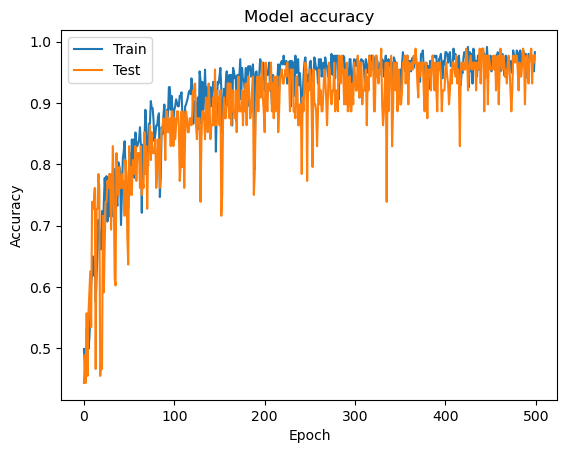

In [39]:
plt.plot(simple_history_8.history['accuracy'])
plt.plot(simple_history_8.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

Again, reduction in batch size seems to speed up the convergence time of the accuracy, with the improvements leveling off at 300 epochs this time.

Epoch 1/1000
6/6 [==============================] - 0s 19ms/step - loss: 14.8364 - accuracy: 0.4815 - val_loss: 7.5959 - val_accuracy: 0.5682
Epoch 2/1000
6/6 [==============================] - 0s 4ms/step - loss: 6.4008 - accuracy: 0.4815 - val_loss: 1.2074 - val_accuracy: 0.5682
Epoch 3/1000
6/6 [==============================] - 0s 4ms/step - loss: 1.6003 - accuracy: 0.4843 - val_loss: 3.5134 - val_accuracy: 0.4318
Epoch 4/1000
6/6 [==============================] - 0s 4ms/step - loss: 2.6472 - accuracy: 0.5185 - val_loss: 1.9657 - val_accuracy: 0.4318
Epoch 5/1000
6/6 [==============================] - 0s 3ms/step - loss: 1.0689 - accuracy: 0.5271 - val_loss: 1.1294 - val_accuracy: 0.5568
Epoch 6/1000
6/6 [==============================] - 0s 4ms/step - loss: 1.2918 - accuracy: 0.4758 - val_loss: 0.7201 - val_accuracy: 0.5455
Epoch 7/1000
6/6 [==============================] - 0s 4ms/step - loss: 0.8214 - accuracy: 0.5100 - val_loss: 1.1303 - val_accuracy: 0.4318
Epoch 8/1000
6/6 [

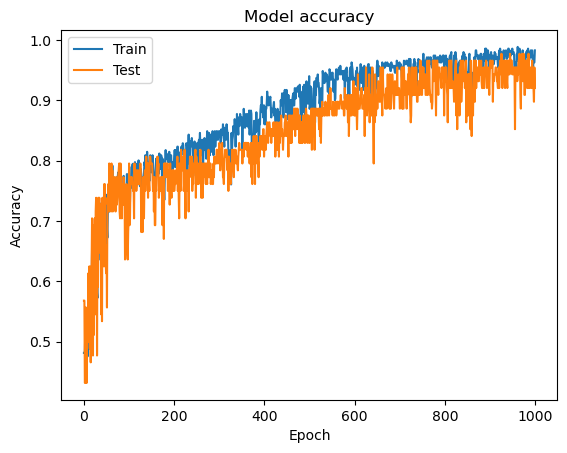

In [40]:
# Define the MLP model
simple_model_64 = Sequential()
simple_model_64.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model_64.add(Dense(32, activation='relu'))
simple_model_64.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model_64.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history_64 = simple_model_64.fit(X_train, y_train, epochs=1000, batch_size=64, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model_64.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

plt.plot(simple_history_64.history['accuracy'])
plt.plot(simple_history_64.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

**Model 2: We Need To Go Deeper**

Let's try out a different MLP structure by adding a few more hidden layers to the model to try to make the learning process more robust.

Epoch 1/1000
22/22 [==============================] - 1s 5ms/step - loss: 1.1175 - accuracy: 0.5128 - val_loss: 0.7328 - val_accuracy: 0.4318
Epoch 2/1000
22/22 [==============================] - 0s 1ms/step - loss: 0.7000 - accuracy: 0.5185 - val_loss: 0.7009 - val_accuracy: 0.4318
Epoch 3/1000
22/22 [==============================] - 0s 1ms/step - loss: 0.6945 - accuracy: 0.4929 - val_loss: 0.7293 - val_accuracy: 0.4318
Epoch 4/1000
22/22 [==============================] - 0s 1ms/step - loss: 0.6926 - accuracy: 0.5185 - val_loss: 0.7000 - val_accuracy: 0.4318
Epoch 5/1000
22/22 [==============================] - 0s 1ms/step - loss: 0.6952 - accuracy: 0.5185 - val_loss: 0.6920 - val_accuracy: 0.5909
Epoch 6/1000
22/22 [==============================] - 0s 1ms/step - loss: 0.6966 - accuracy: 0.5128 - val_loss: 0.7132 - val_accuracy: 0.4318
Epoch 7/1000
22/22 [==============================] - 0s 1ms/step - loss: 0.6901 - accuracy: 0.5185 - val_loss: 0.7088 - val_accuracy: 0.4318
Epoch 

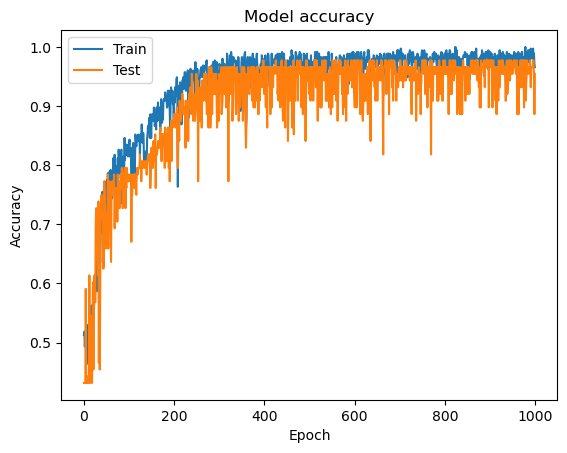

In [43]:
deep_model = Sequential()
deep_model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
deep_model.add(Dense(32, activation='relu'))
deep_model.add(Dense(16, activation='relu'))  # additional layer 1
deep_model.add(Dense(16, activation='relu'))  # additional layer 2
deep_model.add(Dense(1, activation='sigmoid'))

# Compile the model
deep_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train the model
deep_history = deep_model.fit(X_train, y_train, epochs=1000, batch_size=16, validation_data=(X_test, y_test))

# Evaluate the model
scores = deep_model.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

plt.plot(deep_history.history['accuracy'])
plt.plot(deep_history.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

In [44]:
# from sklearn.model_selection import StratifiedKFold

# # Define the MLP model with additional layers
# model = Sequential()
# model.add(Dense(64, input_dim=X.shape[1], activation='relu'))
# model.add(Dense(32, activation='relu'))
# model.add(Dense(16, activation='relu'))  # additional layer 1
# model.add(Dense(16, activation='relu'))  # additional layer 2
# model.add(Dense(1, activation='sigmoid'))

# # Compile the model
# model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# # Train the model
# history = model.fit(X_train, y_train, epochs=200, batch_size=32, validation_data=(X_test, y_test))

# # Evaluate the model
# scores = model.evaluate(X_test, y_test, verbose=0)
# print('Test accuracy:', scores[1])

**Model 3: More Neurons**

It's possible that the true structure of the data is not being captured yet because our model is too simplistic. Let's try adding even more layers and putting even more neurons in each layer! 

Epoch 1/500
22/22 [==============================] - 1s 9ms/step - loss: 1.1712 - accuracy: 0.4957 - val_loss: 0.7458 - val_accuracy: 0.4318
Epoch 2/500
22/22 [==============================] - 0s 4ms/step - loss: 0.8525 - accuracy: 0.5014 - val_loss: 0.6866 - val_accuracy: 0.5682
Epoch 3/500
22/22 [==============================] - 0s 4ms/step - loss: 0.8214 - accuracy: 0.4900 - val_loss: 0.7021 - val_accuracy: 0.4318
Epoch 4/500
22/22 [==============================] - 0s 4ms/step - loss: 0.6970 - accuracy: 0.4986 - val_loss: 0.8854 - val_accuracy: 0.4318
Epoch 5/500
22/22 [==============================] - 0s 4ms/step - loss: 0.7122 - accuracy: 0.5385 - val_loss: 0.7248 - val_accuracy: 0.5682
Epoch 6/500
22/22 [==============================] - 0s 4ms/step - loss: 0.7129 - accuracy: 0.4900 - val_loss: 0.6803 - val_accuracy: 0.5682
Epoch 7/500
22/22 [==============================] - 0s 4ms/step - loss: 0.7177 - accuracy: 0.5385 - val_loss: 0.7000 - val_accuracy: 0.4545
Epoch 8/500
2

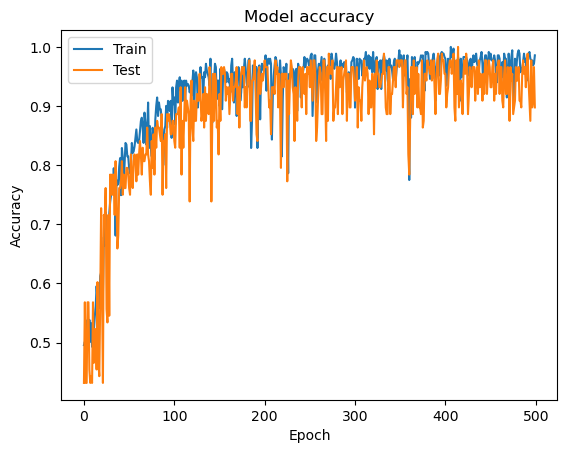

In [45]:
wide_model = Sequential()
wide_model.add(Dense(1024, input_dim=X_train.shape[1], activation='relu'))
wide_model.add(Dense(512, activation='relu'))
wide_model.add(Dense(256, activation='relu'))
wide_model.add(Dense(128, activation='relu'))
wide_model.add(Dense(64, activation='relu'))  # additional layer 1
wide_model.add(Dense(32, activation='relu'))  # additional layer 2
wide_model.add(Dense(1, activation='sigmoid'))

# Compile the model
wide_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Train the model
wide_history = wide_model.fit(X_train, y_train, epochs=500, batch_size=16, validation_data=(X_test, y_test))

# Evaluate the model
scores = wide_model.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

plt.plot(wide_history.history['accuracy'])
plt.plot(wide_history.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

So far, adding more layers or putting more "neurons" in each of the layers hasn't had much of a positive impact. Our best model so far was the simple model with a batch size of 16 and 1000 epochs of training. We can still try a few more tricks before we accept our final model, namely switching the optimizer and changing our train/test split. Up to this point, our optimizer has been Adam, or Adaptive Moment Esitmation. Adam is an algorithm that builds off of a combination of stochastic gradient descent (SGD) and RMSprop by adjusting the learning rate over time using the first and second moments of the gradient. Regular SGD can suffer from slow convergence or even divergence with a poorly chosen learning rate that remains fixed through the learning process. Adam's adaptive learning rate speeds up convergence time and reduces the chances of divergence as well. Adam was released to the general public in 2014 by Diederik Kingma, writing "The method is straightforward to implement, is computationally efficient, has little memory requirements, is invariant to diagonal rescaling of the gradients, and is well suited for problems that are large in terms of data and/or parameters." in Kingma et al., 2014. Since Adam is especially good at reducing oscillatory behavior during update steps, it seems like a great choice of optimizer for our modeling process, considering that we are still dealing with oscillation issues even using Adam. However, we should still fulfill our due diligence and test out some other optimizers to make sure Adam is the right tool for the job; let's try out Stochastic Gradient Descent, Adagrad, Adadelta, and RMSprop.

Epoch 1/100
22/22 [==============================] - 0s 5ms/step - loss: 8.5416 - accuracy: 0.4758 - val_loss: 0.9627 - val_accuracy: 0.4318
Epoch 2/100
22/22 [==============================] - 0s 1ms/step - loss: 0.7042 - accuracy: 0.5214 - val_loss: 0.7336 - val_accuracy: 0.4318
Epoch 3/100
22/22 [==============================] - 0s 1ms/step - loss: 0.6941 - accuracy: 0.5214 - val_loss: 0.6910 - val_accuracy: 0.5114
Epoch 4/100
22/22 [==============================] - 0s 1ms/step - loss: 0.7002 - accuracy: 0.5157 - val_loss: 0.7207 - val_accuracy: 0.4545
Epoch 5/100
22/22 [==============================] - 0s 1ms/step - loss: 0.6838 - accuracy: 0.5670 - val_loss: 0.6958 - val_accuracy: 0.5568
Epoch 6/100
22/22 [==============================] - 0s 1ms/step - loss: 0.6914 - accuracy: 0.5385 - val_loss: 0.7006 - val_accuracy: 0.4886
Epoch 7/100
22/22 [==============================] - 0s 1ms/step - loss: 0.6886 - accuracy: 0.5726 - val_loss: 0.6926 - val_accuracy: 0.4659
Epoch 8/100
2

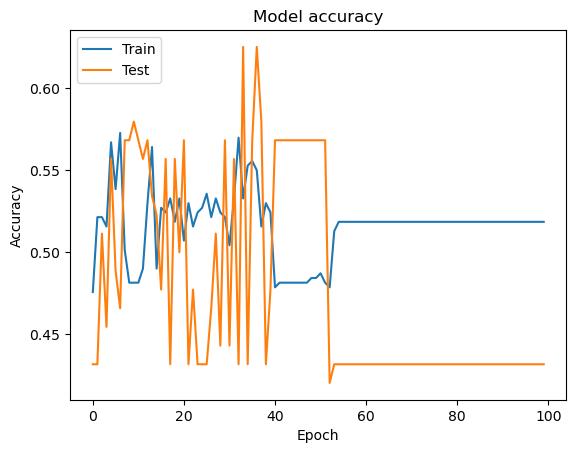

In [46]:
# Define the MLP model
simple_model_sgd = Sequential()
simple_model_sgd.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model_sgd.add(Dense(32, activation='relu'))
simple_model_sgd.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model_sgd.compile(loss='binary_crossentropy', optimizer='sgd', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history_sgd = simple_model_sgd.fit(X_train, y_train, epochs=100, batch_size=16, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model_sgd.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

plt.plot(simple_history_sgd.history['accuracy'])
plt.plot(simple_history_sgd.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

Interestingly, by using the base SGD as our optimizatizer, the training and testing accuracy values become significantly more stable. However, they suffer from the fairly large negative tradeoff of having quite poor accuracy values. Again, we see a model that has test results worse than randomly guessing, so base SGD is not a good fit for our modeling purposes. Let's try a few more optimizer choices and then reconvene.

Epoch 1/100
22/22 [==============================] - 0s 5ms/step - loss: 1.7846 - accuracy: 0.5840 - val_loss: 0.7087 - val_accuracy: 0.4886
Epoch 2/100
22/22 [==============================] - 0s 1ms/step - loss: 0.6749 - accuracy: 0.5670 - val_loss: 0.6523 - val_accuracy: 0.6364
Epoch 3/100
22/22 [==============================] - 0s 1ms/step - loss: 0.6669 - accuracy: 0.5726 - val_loss: 0.6557 - val_accuracy: 0.6023
Epoch 4/100
22/22 [==============================] - 0s 1ms/step - loss: 0.6712 - accuracy: 0.5869 - val_loss: 0.6490 - val_accuracy: 0.6250
Epoch 5/100
22/22 [==============================] - 0s 1ms/step - loss: 0.6632 - accuracy: 0.5783 - val_loss: 0.6590 - val_accuracy: 0.6136
Epoch 6/100
22/22 [==============================] - 0s 1ms/step - loss: 0.6617 - accuracy: 0.5385 - val_loss: 0.6504 - val_accuracy: 0.6136
Epoch 7/100
22/22 [==============================] - 0s 1ms/step - loss: 0.6651 - accuracy: 0.5584 - val_loss: 0.6490 - val_accuracy: 0.6250
Epoch 8/100
2

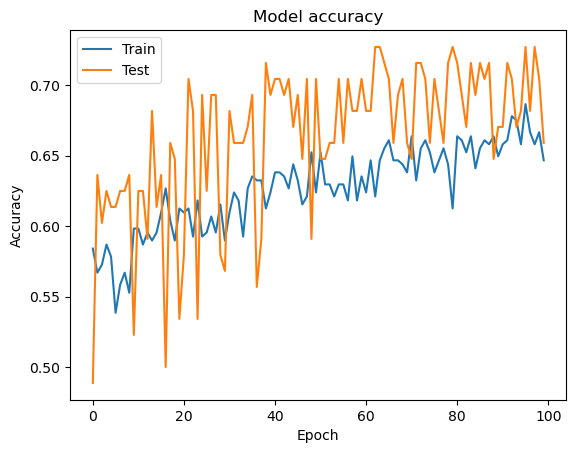

In [47]:
# Define the MLP model
simple_model_adagrad = Sequential()
simple_model_adagrad.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model_adagrad.add(Dense(32, activation='relu'))
simple_model_adagrad.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model_adagrad.compile(loss='binary_crossentropy', optimizer='adagrad', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history_adagrad = simple_model_adagrad.fit(X_train, y_train, epochs=100, batch_size=16, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model_adagrad.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

plt.plot(simple_history_adagrad.history['accuracy'])
plt.plot(simple_history_adagrad.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

Epoch 1/100
22/22 [==============================] - 1s 5ms/step - loss: 16.4428 - accuracy: 0.5185 - val_loss: 20.3944 - val_accuracy: 0.4318
Epoch 2/100
22/22 [==============================] - 0s 1ms/step - loss: 16.3903 - accuracy: 0.5185 - val_loss: 20.3283 - val_accuracy: 0.4318
Epoch 3/100
22/22 [==============================] - 0s 1ms/step - loss: 16.3367 - accuracy: 0.5185 - val_loss: 20.2612 - val_accuracy: 0.4318
Epoch 4/100
22/22 [==============================] - 0s 1ms/step - loss: 16.2824 - accuracy: 0.5185 - val_loss: 20.1932 - val_accuracy: 0.4318
Epoch 5/100
22/22 [==============================] - 0s 1ms/step - loss: 16.2272 - accuracy: 0.5185 - val_loss: 20.1241 - val_accuracy: 0.4318
Epoch 6/100
22/22 [==============================] - 0s 1ms/step - loss: 16.1713 - accuracy: 0.5185 - val_loss: 20.0541 - val_accuracy: 0.4318
Epoch 7/100
22/22 [==============================] - 0s 1ms/step - loss: 16.1148 - accuracy: 0.5185 - val_loss: 19.9832 - val_accuracy: 0.4318

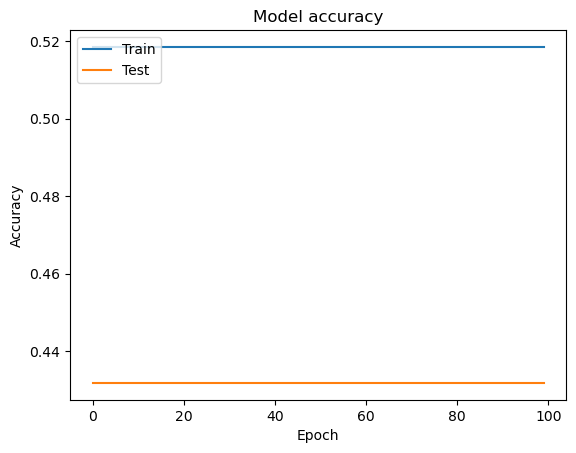

In [48]:
# Define the MLP model
simple_model_adadelta = Sequential()
simple_model_adadelta.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model_adadelta.add(Dense(32, activation='relu'))
simple_model_adadelta.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model_adadelta.compile(loss='binary_crossentropy', optimizer='adadelta', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history_adadelta = simple_model_adadelta.fit(X_train, y_train, epochs=100, batch_size=16, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model_adadelta.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

plt.plot(simple_history_adadelta.history['accuracy'])
plt.plot(simple_history_adadelta.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

Epoch 1/100
22/22 [==============================] - 0s 5ms/step - loss: 1.8595 - accuracy: 0.5556 - val_loss: 1.0787 - val_accuracy: 0.4659
Epoch 2/100
22/22 [==============================] - 0s 1ms/step - loss: 1.5555 - accuracy: 0.4872 - val_loss: 1.6419 - val_accuracy: 0.4545
Epoch 3/100
22/22 [==============================] - 0s 1ms/step - loss: 1.1752 - accuracy: 0.5328 - val_loss: 1.7206 - val_accuracy: 0.4545
Epoch 4/100
22/22 [==============================] - 0s 1ms/step - loss: 1.0153 - accuracy: 0.5812 - val_loss: 1.2602 - val_accuracy: 0.5795
Epoch 5/100
22/22 [==============================] - 0s 1ms/step - loss: 1.1475 - accuracy: 0.6097 - val_loss: 0.7614 - val_accuracy: 0.5795
Epoch 6/100
22/22 [==============================] - 0s 1ms/step - loss: 1.3158 - accuracy: 0.5698 - val_loss: 1.0560 - val_accuracy: 0.5795
Epoch 7/100
22/22 [==============================] - 0s 1ms/step - loss: 1.2870 - accuracy: 0.5670 - val_loss: 1.4247 - val_accuracy: 0.5795
Epoch 8/100
2

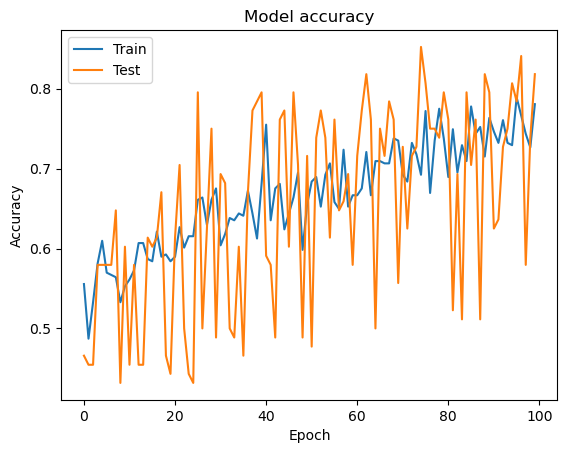

In [49]:
# Define the MLP model
simple_model_rms = Sequential()
simple_model_rms.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model_rms.add(Dense(32, activation='relu'))
simple_model_rms.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model_rms.compile(loss='binary_crossentropy', optimizer='rmsprop', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history_rms = simple_model_rms.fit(X_train, y_train, epochs=100, batch_size=16, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model_rms.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

plt.plot(simple_history_rms.history['accuracy'])
plt.plot(simple_history_rms.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

We can see in no uncertain terms that every new optimizer performed significantly and remarkably worse than our starting choice of Adam, so from now on we will stick with that as our optimizer for the rest of the modeling process. Another try we can do to reduce update roughness is changing the split of the training and testing data. Since our dataset is relatively small for a neural network architecture, there is a possibility that the test set is small enough that a couple of extra correct or incorrect classification can cause larger swings in the accuracy results than we would like. Adjusting the percentage of the dataset in the test set could potentially ameliorate the issue.

X_train shape: (307, 15)
y_train shape: (307,)
X_test shape: (132, 15)
y_test shape: (132,)
Epoch 1/1000
20/20 [==============================] - 0s 5ms/step - loss: 4.9684 - accuracy: 0.4756 - val_loss: 1.5332 - val_accuracy: 0.5530
Epoch 2/1000
20/20 [==============================] - 0s 1ms/step - loss: 1.0049 - accuracy: 0.4984 - val_loss: 0.8547 - val_accuracy: 0.5379
Epoch 3/1000
20/20 [==============================] - 0s 2ms/step - loss: 0.7644 - accuracy: 0.5114 - val_loss: 0.8702 - val_accuracy: 0.4924
Epoch 4/1000
20/20 [==============================] - 0s 2ms/step - loss: 0.7321 - accuracy: 0.5179 - val_loss: 0.8856 - val_accuracy: 0.4924
Epoch 5/1000
20/20 [==============================] - 0s 2ms/step - loss: 0.7518 - accuracy: 0.5472 - val_loss: 0.7030 - val_accuracy: 0.5152
Epoch 6/1000
20/20 [==============================] - 0s 2ms/step - loss: 0.6888 - accuracy: 0.5798 - val_loss: 1.0498 - val_accuracy: 0.4470
Epoch 7/1000
20/20 [==============================] - 0s

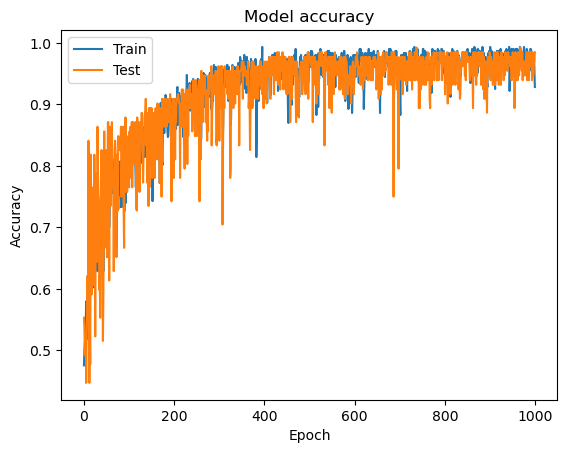

In [50]:
# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1234)

# Check the shapes
print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_test shape:', X_test.shape)
print('y_test shape:', y_test.shape)

simple_model = Sequential()
simple_model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model.add(Dense(32, activation='relu'))
simple_model.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history = simple_model.fit(X_train, y_train, epochs=1000, batch_size=16, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

plt.plot(simple_history.history['accuracy'])
plt.plot(simple_history.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

X_train shape: (263, 15)
y_train shape: (263,)
X_test shape: (176, 15)
y_test shape: (176,)
Epoch 1/1000
17/17 [==============================] - 0s 6ms/step - loss: 5.0956 - accuracy: 0.4829 - val_loss: 2.1227 - val_accuracy: 0.4830
Epoch 2/1000
17/17 [==============================] - 0s 2ms/step - loss: 1.6070 - accuracy: 0.5095 - val_loss: 1.5585 - val_accuracy: 0.4830
Epoch 3/1000
17/17 [==============================] - 0s 2ms/step - loss: 1.1431 - accuracy: 0.4753 - val_loss: 0.7102 - val_accuracy: 0.4659
Epoch 4/1000
17/17 [==============================] - 0s 2ms/step - loss: 0.8328 - accuracy: 0.5285 - val_loss: 0.6675 - val_accuracy: 0.6193
Epoch 5/1000
17/17 [==============================] - 0s 2ms/step - loss: 0.7679 - accuracy: 0.4981 - val_loss: 0.6482 - val_accuracy: 0.6307
Epoch 6/1000
17/17 [==============================] - 0s 2ms/step - loss: 0.6985 - accuracy: 0.5627 - val_loss: 0.6319 - val_accuracy: 0.6989
Epoch 7/1000
17/17 [==============================] - 0s

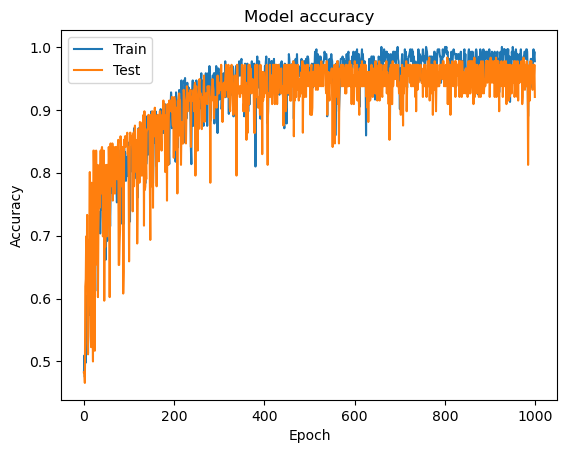

In [51]:
# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.4, random_state=1234)

# Check the shapes
print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_test shape:', X_test.shape)
print('y_test shape:', y_test.shape)

simple_model = Sequential()
simple_model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model.add(Dense(32, activation='relu'))
simple_model.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history = simple_model.fit(X_train, y_train, epochs=1000, batch_size=16, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

plt.plot(simple_history.history['accuracy'])
plt.plot(simple_history.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

X_train shape: (395, 15)
y_train shape: (395,)
X_test shape: (44, 15)
y_test shape: (44,)
Epoch 1/1000
25/25 [==============================] - 1s 5ms/step - loss: 1.7662 - accuracy: 0.5114 - val_loss: 0.6977 - val_accuracy: 0.5455
Epoch 2/1000
25/25 [==============================] - 0s 1ms/step - loss: 0.7421 - accuracy: 0.5418 - val_loss: 0.6850 - val_accuracy: 0.5227
Epoch 3/1000
25/25 [==============================] - 0s 1ms/step - loss: 0.7456 - accuracy: 0.5063 - val_loss: 0.5971 - val_accuracy: 0.7045
Epoch 4/1000
25/25 [==============================] - 0s 1ms/step - loss: 0.6892 - accuracy: 0.5975 - val_loss: 0.6949 - val_accuracy: 0.5455
Epoch 5/1000
25/25 [==============================] - 0s 1ms/step - loss: 0.6923 - accuracy: 0.5823 - val_loss: 0.5551 - val_accuracy: 0.7273
Epoch 6/1000
25/25 [==============================] - 0s 1ms/step - loss: 0.6808 - accuracy: 0.6101 - val_loss: 0.8029 - val_accuracy: 0.3864
Epoch 7/1000
25/25 [==============================] - 0s 1

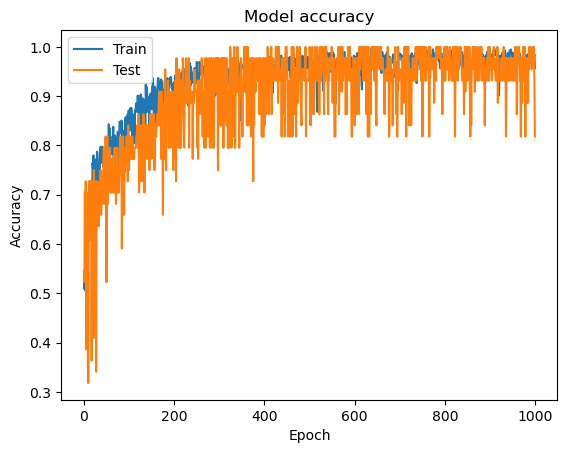

In [52]:
# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=1234)

# Check the shapes
print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_test shape:', X_test.shape)
print('y_test shape:', y_test.shape)

simple_model = Sequential()
simple_model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model.add(Dense(32, activation='relu'))
simple_model.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history = simple_model.fit(X_train, y_train, epochs=1000, batch_size=16, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

plt.plot(simple_history.history['accuracy'])
plt.plot(simple_history.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

X_train shape: (373, 15)
y_train shape: (373,)
X_test shape: (66, 15)
y_test shape: (66,)
Epoch 1/1000
24/24 [==============================] - 0s 5ms/step - loss: 1.1567 - accuracy: 0.5040 - val_loss: 0.8772 - val_accuracy: 0.4091
Epoch 2/1000
24/24 [==============================] - 0s 1ms/step - loss: 0.7096 - accuracy: 0.5496 - val_loss: 0.6637 - val_accuracy: 0.6515
Epoch 3/1000
24/24 [==============================] - 0s 1ms/step - loss: 0.6764 - accuracy: 0.5952 - val_loss: 0.6929 - val_accuracy: 0.5152
Epoch 4/1000
24/24 [==============================] - 0s 1ms/step - loss: 0.8231 - accuracy: 0.5684 - val_loss: 1.1827 - val_accuracy: 0.4091
Epoch 5/1000
24/24 [==============================] - 0s 1ms/step - loss: 0.7484 - accuracy: 0.5576 - val_loss: 0.8853 - val_accuracy: 0.4091
Epoch 6/1000
24/24 [==============================] - 0s 1ms/step - loss: 0.7078 - accuracy: 0.5550 - val_loss: 0.5866 - val_accuracy: 0.6667
Epoch 7/1000
24/24 [==============================] - 0s 1

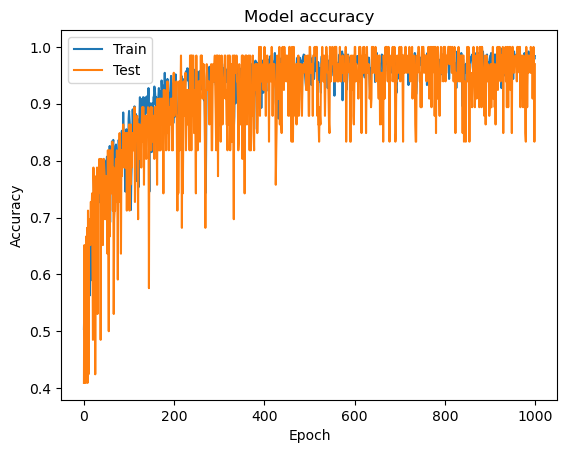

In [53]:
# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=1234)

# Check the shapes
print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_test shape:', X_test.shape)
print('y_test shape:', y_test.shape)

simple_model = Sequential()
simple_model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
simple_model.add(Dense(32, activation='relu'))
simple_model.add(Dense(1, activation='sigmoid'))

# Compile the model
simple_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
simple_history = simple_model.fit(X_train, y_train, epochs=1000, batch_size=16, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = simple_model.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

plt.plot(simple_history.history['accuracy'])
plt.plot(simple_history.history['val_accuracy'])
plt.title('Model accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend(['Train', 'Test'], loc='upper left')
plt.show()

Now that all of our hyperparameter tuning has finished and we've played around with some of the other parameters, we're ready to run our final model. Let's toss in some extra evaluation metrics so we can get the full scope of the model's true power. We want to use precision and recall as two of the gold standard binary classification evaluators, and another crowd favorite in AUC.

In [57]:
# Split train/test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1234)

# Check the shapes
print('X_train shape:', X_train.shape)
print('y_train shape:', y_train.shape)
print('X_test shape:', X_test.shape)
print('y_test shape:', y_test.shape)

final_model = Sequential()
final_model.add(Dense(64, input_dim=X_train.shape[1], activation='relu'))
final_model.add(Dense(32, activation='relu'))
final_model.add(Dense(1, activation='sigmoid'))

from keras import metrics

# Compile the model
final_model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy', metrics.Precision(), metrics.Recall(), metrics.AUC()])

# Define early stopping criteria
# early_stopping = EarlyStopping(monitor='val_loss', patience=5, mode='min')

# Train the model
final_history = final_model.fit(X_train, y_train, epochs=1000, batch_size=16, validation_data=(X_test, y_test)) # , callbacks=[early_stopping]

# Evaluate the model
scores = final_model.evaluate(X_test, y_test, verbose=0)
print('Test accuracy:', scores[1])

X_train shape: (351, 15)
y_train shape: (351,)
X_test shape: (88, 15)
y_test shape: (88,)
Epoch 1/1000
22/22 [==============================] - 1s 9ms/step - loss: 1.4927 - accuracy: 0.5726 - precision_2: 0.5825 - recall_2: 0.6209 - auc_2: 0.5803 - val_loss: 0.9715 - val_accuracy: 0.4318 - val_precision_2: 0.4318 - val_recall_2: 1.0000 - val_auc_2: 0.5416
Epoch 2/1000
22/22 [==============================] - 0s 2ms/step - loss: 0.8418 - accuracy: 0.4872 - precision_2: 0.5051 - recall_2: 0.5495 - auc_2: 0.4817 - val_loss: 0.6684 - val_accuracy: 0.5682 - val_precision_2: 0.0000e+00 - val_recall_2: 0.0000e+00 - val_auc_2: 0.6429
Epoch 3/1000
22/22 [==============================] - 0s 2ms/step - loss: 0.6752 - accuracy: 0.5755 - precision_2: 0.5882 - recall_2: 0.6044 - auc_2: 0.6039 - val_loss: 0.8017 - val_accuracy: 0.4432 - val_precision_2: 0.4353 - val_recall_2: 0.9737 - val_auc_2: 0.6539
Epoch 4/1000
22/22 [==============================] - 0s 2ms/step - loss: 0.6659 - accuracy: 0.609

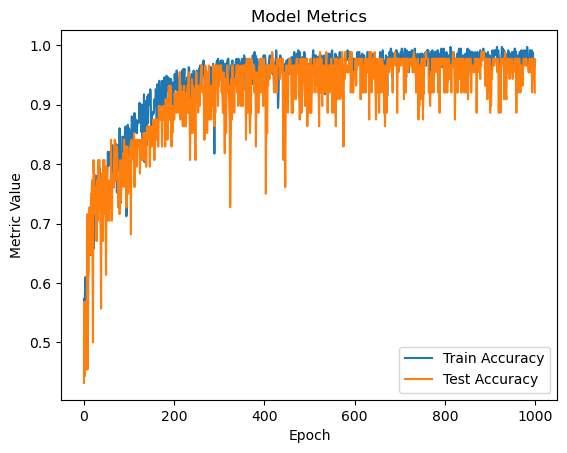

In [61]:
# Plot the accuracy, precision, recall, and AUC over time
plt.plot(final_history.history['accuracy'])
plt.plot(final_history.history['val_accuracy'])

plt.title('Model Metrics')
plt.xlabel('Epoch')
plt.ylabel('Metric Value')
plt.legend(['Train Accuracy', 'Test Accuracy'], loc='lower right')
plt.show()

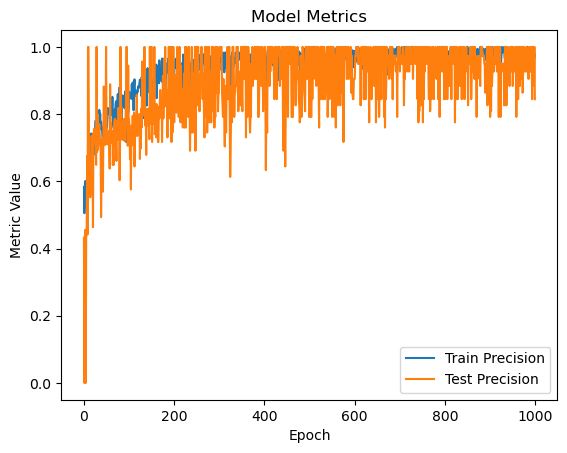

In [62]:
plt.plot(final_history.history['precision_2'])
plt.plot(final_history.history['val_precision_2'])

plt.title('Model Metrics')
plt.xlabel('Epoch')
plt.ylabel('Metric Value')
plt.legend(['Train Precision', 'Test Precision'], loc='lower right')
plt.show()

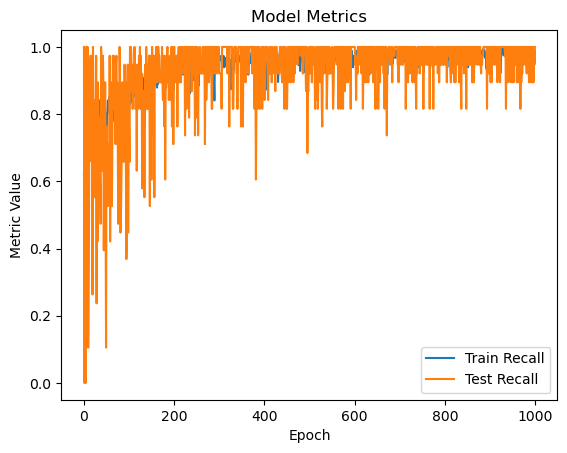

In [63]:
plt.plot(final_history.history['recall_2'])
plt.plot(final_history.history['val_recall_2'])

plt.title('Model Metrics')
plt.xlabel('Epoch')
plt.ylabel('Metric Value')
plt.legend(['Train Recall', 'Test Recall'], loc='lower right')
plt.show()

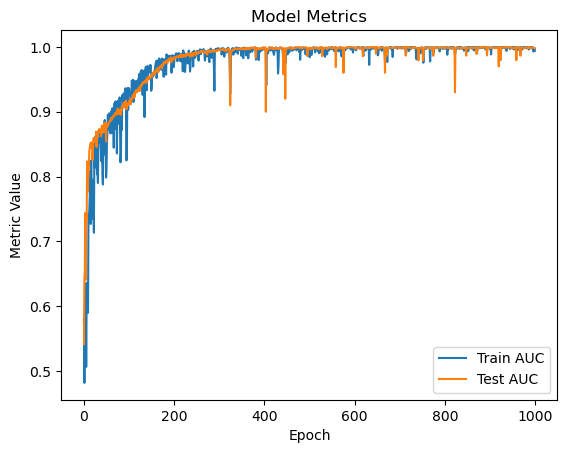

In [64]:
plt.plot(final_history.history['auc_2'])
plt.plot(final_history.history['val_auc_2'])

plt.title('Model Metrics')
plt.xlabel('Epoch')
plt.ylabel('Metric Value')
plt.legend(['Train AUC', 'Test AUC'], loc='lower right')
plt.show()

**Conclusion**

Multilayer Perceptrons are powerful and flexible models that can be used for a variety of deep learning tasks, including binary classification. They are relatively simple  and quick to build and train, and can achieve high levels of accuracy when properly configured. However, MLPs can also be prone to overfitting, especially when working with small datasets or complex models. To mitigate this issue, it is important to carefully choose the number of hidden layers and nodes, select appropriate activation functions, and use techniques such as early stopping, regularization, and dropout. Overall, MLPs are a valuable tool for machine learning practitioners and can be used to solve a wide range of classification problems.

While we were able to avoid overfitting issues, we never managed to overcome the choppiness of the accuracy values for the training or the testing sets across epochs. We tested several different architectures by changing the number of layers and how many units were in each layer, tested multiple optimization options, number of epochs, batch size, etc. Although we were able to improve the model to quite strong values for our evaluation criteria (AUC, precision, recall, accuracy), the spikes in the accuracy curves were resilent, suggesting that ultimately the data is simply noisy or too small. We learned that sometimes we will simply not be able to fix certain issues in the modeling process even when we throw the kitchen sink at it. Despite the spiky accuracy curves, our end results were ultimately highly performant in all of our evaluation metrics. 

We could have tried to add in ridge or lasso regularization, or used dropout in an attempt to expel the spiky accuracy problem. Early stopping was attempted, but it was a struggle to interface that technique with the spiking and it was often non-trivial where to cutoff the learning for many of the model runs, so it was ultimately scrapped. Another idea could have been to try transforming the data before running it through the MLP architecture, such as doing a feature space reduction with PCA to lower the dimensions of the input data.

**References**

https://en.wikipedia.org/wiki/Multilayer_perceptron

https://www.dataversity.net/brief-history-deep-learning/

https://www.tensorflow.org/api_docs/python/tf/keras/optimizers/Adam